In [41]:
import CPanalysistools
from CPanalysistools import *
import seaborn as sns

# 1. Load simulation workflows/result files

In [29]:
pheno_file = './phenopowerlaw/phenopowerlaw_128_rolled_copper_200_grains_5k_time_steps_2026-08-28_104710/execute/t_1/geom_load.hdf5'
pheno_wk = './phenopowerlaw/phenopowerlaw_128_rolled_copper_200_grains_5k_time_steps_2026-08-28_104710'
dislo_file = './dislo_density/dislotwin_128_rolled_copper_200_grains_5k_time_steps_2026-08-28_104634/execute/t_1/geom_load.hdf5'
dislo_wk = './dislo_density/dislotwin_128_rolled_copper_200_grains_5k_time_steps_2026-08-28_104634'

# 2. Extract/load relevant values and produce plots

### Create .vti file of VE

In [12]:
material_IDs = np.load("../data/material_IDs_200_grains_128_cubed_VE.npy")

In [13]:
# Phenopowerlaw
material_IDs_grid = pv.ImageData()
material_IDs_grid.dimensions = (material_IDs.shape[0]+1, material_IDs.shape[1]+1, material_IDs.shape[2]+1)
material_IDs_grid.spacing = (1.0e-3/material_IDs.shape[0], 1.0e-3/material_IDs.shape[1], 1.0e-3/material_IDs.shape[2])
material_IDs_grid.cell_data["material"] = material_IDs.flatten(order = 'F')

material_IDs_grid.save("../viz_files/polycrystal_rolled_copper_200_grains.vti")

### Stress triaxiality

In [3]:
pheno_triax = CPanalysistools.extractDAMASKdata.extract_stress_triaxiality(pheno_file, [128,128,128])

In [4]:
dislo_triax = CPanalysistools.extractDAMASKdata.extract_stress_triaxiality(dislo_file, [128,128,128])

In [5]:
pheno_triax = np.array(pheno_triax)
dislo_triax = np.array(dislo_triax)

In [ ]:
np.save("pheno_triax_200_grains.npy", pheno_triax)
np.save("dislo_triax_200_grains.npy", dislo_triax)

In [20]:
pheno_triax = np.load("../data/stress_triaxiality/pheno_triax_200_grains.npy")
dislo_triax = np.load("../data/stress_triaxiality/dislo_triax_200_grains.npy")

In [10]:
# Phenopowerlaw
pheno_full_triax_grid = pv.ImageData()
pheno_full_triax_grid.dimensions = (pheno_triax.shape[0]+1, pheno_triax.shape[1]+1, pheno_triax.shape[2]+1)
pheno_full_triax_grid.spacing = (1.0e-3/pheno_triax.shape[0], 1.0e-3/pheno_triax.shape[1], 1.0e-3/pheno_triax.shape[2])
pheno_full_triax_grid.cell_data["triax_values"] = pheno_triax.flatten(order = 'F')

pheno_full_triax_grid.save("../viz_files/phenopowerlaw/pheno_128_triax_200_grains.vti")

In [11]:
# Dislotwin
dislo_full_triax_grid = pv.ImageData()
dislo_full_triax_grid.dimensions = (dislo_triax.shape[0]+1, dislo_triax.shape[1]+1, dislo_triax.shape[2]+1)
dislo_full_triax_grid.spacing = (1.0e-3/dislo_triax.shape[0], 1.0e-3/dislo_triax.shape[1], 1.0e-3/dislo_triax.shape[2])
dislo_full_triax_grid.cell_data["triax_values"] = dislo_triax.flatten(order = 'F')

dislo_full_triax_grid.save("../viz_files/dislo_density/dislo_128_triax_200_grains.vti")

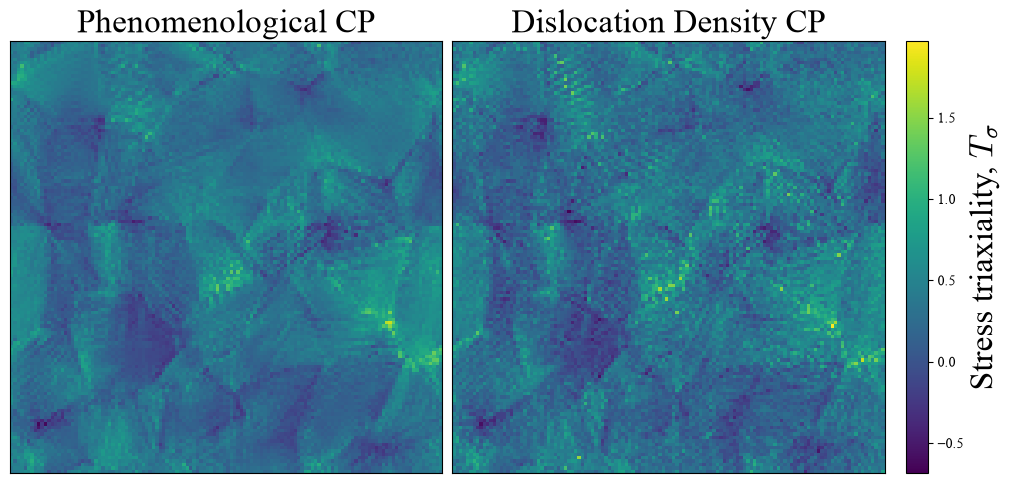

In [5]:
%matplotlib inline
fig_triax = CPanalysistools.comparison_map(np.flip(pheno_triax[:,:,0].transpose(), axis=0), 
                               np.flip(dislo_triax[:,:,0].transpose(), axis=0),
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'Stress triaxiality, $T_{\sigma}$',
                               #savefig = True,
                               #fig_name = "../figures/surface_stress_triaxiality_comparison_200_grains_128_VE_poster_label_size.png"
                               cbar_fontsize = 24, 
                               title_fontsize = 24)

In [37]:
from matplotlib.ticker import AutoLocator
def comparison_map(data1, data2, data1_label, data2_label, color_bar_label, savefig = False, fig_name = None,
                   cbar_fontsize = 16, cbar_ticks_fontsize = 16, title_fontsize = 16):    
    fig, ax = plt.subplots(1,2, figsize = (10,6), sharey = True, sharex=True, constrained_layout=True)
    im_1 = ax[0].imshow(data1, vmin = min(min(value) for value in (data1.flatten(), data2.flatten())), vmax = max(max(value) for value in(data1.flatten(), data2.flatten())))
    im_2 = ax[1].imshow(data2, vmin = min(min(value) for value in (data1.flatten(), data2.flatten())), vmax = max(max(value) for value in (data1.flatten(), data2.flatten())))
    cbar = fig.colorbar(im_2, orientation = 'vertical', shrink = 0.73)
    cbar.set_label(color_bar_label, rotation = 90, fontsize = cbar_fontsize, math_fontfamily = 'cm')
    cbar.ax.tick_params(labelsize = cbar_ticks_fontsize)
    ax[0].set_title(f'{data1_label}', fontsize = title_fontsize)
    ax[1].set_title(f'{data2_label}', fontsize = title_fontsize)
    ax[0].set_xticks([])
    ax[1].set_xticks([])
    ax[0].set_yticks([])
    ax[1].set_yticks([])

    if savefig==True:
        plt.savefig(fig_name, dpi=800)

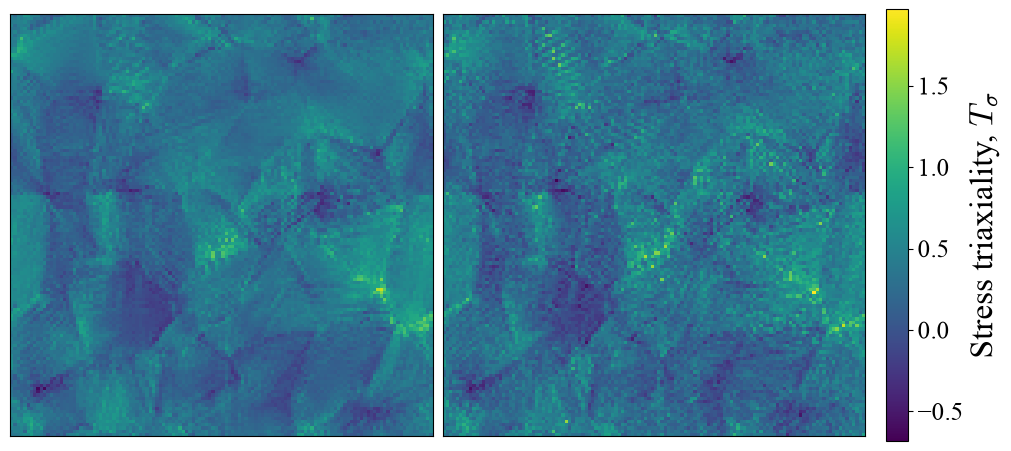

In [52]:
comparison_map(np.flip(pheno_triax[:,:,0].transpose(), axis=0), 
                               np.flip(dislo_triax[:,:,0].transpose(), axis=0),
                               data1_label = "", #'Phenomenological CP',
                               data2_label = "", #'Dislocation Density CP',
                               color_bar_label = r'Stress triaxiality, $T_{\sigma}$',
                               savefig = True,
                               fig_name = "../figures/surface_stress_triaxiality_comparison_200_grains_128_VE_poster_label_size_no_title.png",
                               cbar_fontsize = 24,
                               cbar_ticks_fontsize = 18, 
                               title_fontsize = 24)

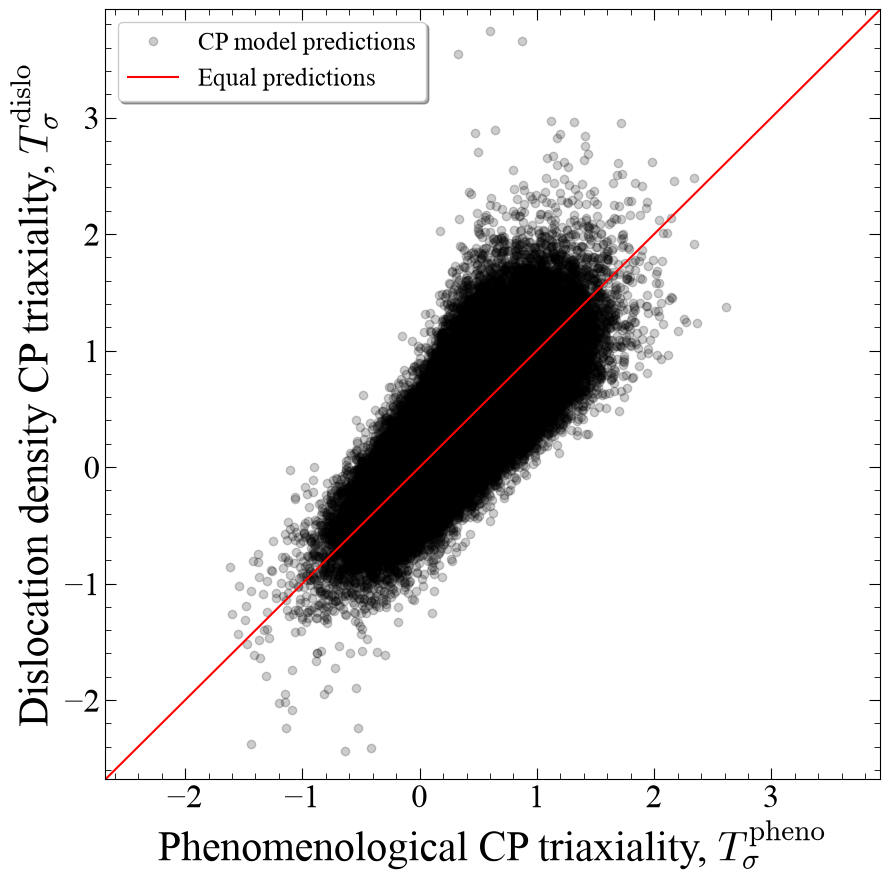

In [49]:
%matplotlib inline
CPanalysistools.comparison_plot(pheno_triax.flatten(order = 'F'), dislo_triax.flatten(order = 'F'), 
                                r"Phenomenological CP triaxiality, $T_{\sigma}^{\text{pheno}}$",
                                r"Dislocation density CP triaxiality, $T_{\sigma}^{\text{dislo}}$",
                                marker_color = 'k',
                                legend_label = 'CP model predictions',
                                marker_transparency = 0.2,
                                axis_label_fontsize = 30,
                                tick_label_fontsize = 24,
                                legend_fontsize = 18,
                                savefig = True,
                                fig_name = "../figures/stress_triaxiality_comparison_200_grains_128_VE_poster_label_size.png"
                                )
                                   
#plt.legend(loc = 'upper left', shadow = True, fontsize = 18)                     

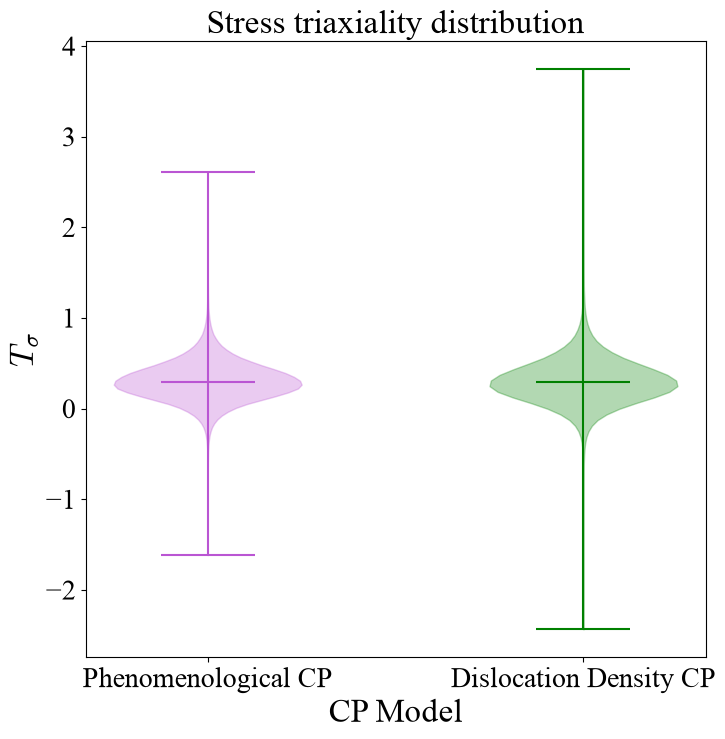

In [38]:
CPanalysistools.comparison_violin_plot(pheno_triax.flatten(order = 'F'), dislo_triax.flatten(order = 'F'), 
                       "Phenomenological CP", 
                       "Dislocation Density CP", 
                       "Stress triaxiality distribution", 
                       r"$T_{\sigma}$",
                       savefig = True,
                       fig_name = "../figures/stress_triaxiality_violin_plot_200_grains_128_VE.png")

### Comparison of max $T_{\sigma}$

In [78]:
pheno_max_triax_idx = np.where(pheno_triax == max(pheno_triax.flatten()))
dislo_max_triax_idx = np.where(dislo_triax == max(dislo_triax.flatten()))
pheno_max_triax_idx, dislo_max_triax_idx

((array([118]), array([74]), array([70])),
 (array([126]), array([20]), array([79])))

In [146]:
triax_min_pheno_max = min(min(value) for value in (pheno_triax[:,:,pheno_max_triax_idx[-1][0]].flatten(), dislo_triax[:,:,pheno_max_triax_idx[-1][0]].flatten()))
triax_max_pheno_max = max(max(value) for value in (pheno_triax[:,:,pheno_max_triax_idx[-1][0]].flatten(), dislo_triax[:,:,pheno_max_triax_idx[-1][0]].flatten()))

triax_min_dislo_max = min(min(value) for value in (pheno_triax[:,:,dislo_max_triax_idx[-1][0]].flatten(), dislo_triax[:,:,dislo_max_triax_idx[-1][0]].flatten()))
triax_max_dislo_max = max(max(value) for value in (pheno_triax[:,:,dislo_max_triax_idx[-1][0]].flatten(), dislo_triax[:,:,dislo_max_triax_idx[-1][0]].flatten()))

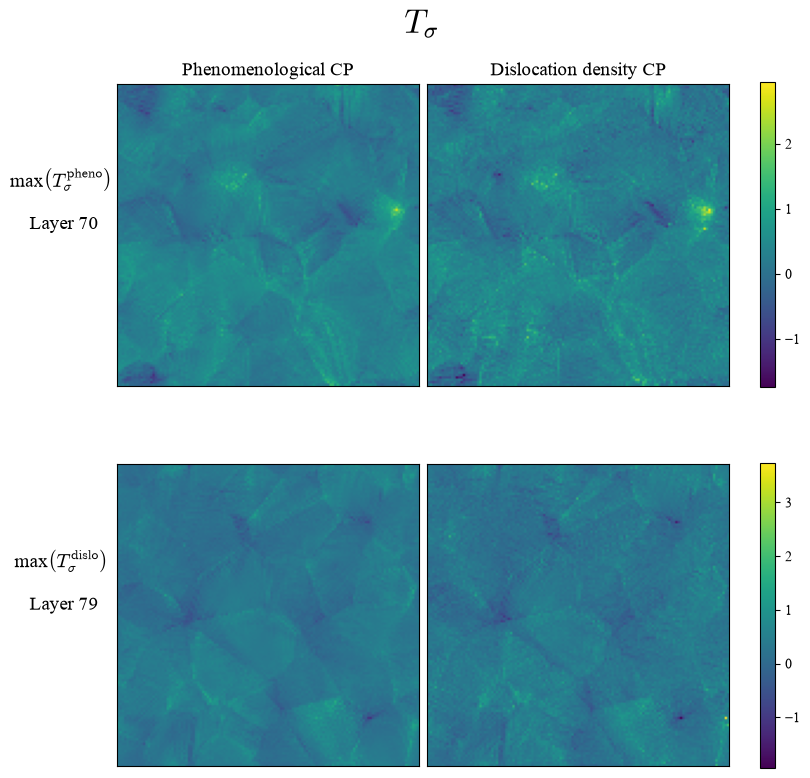

In [190]:
fig_max_triax_comp, ax_max_triax_comp = plt.subplots(2,2, figsize = (8,8), constrained_layout = True)

fig_max_triax_comp.suptitle(r"$T_{\sigma}$", x = 0.52, math_fontfamily = 'cm', fontsize = 24)
ax_max_triax_comp[0,0].set_title("Phenomenological CP", fontsize = 14)
ax_max_triax_comp[0,1].set_title("Dislocation density CP", fontsize = 14)
im_pheno_pheno_max_triax = ax_max_triax_comp[0,0].imshow(np.flip(pheno_triax[:,:,pheno_max_triax_idx[-1][0]].transpose(), axis=0), vmin = triax_min_pheno_max, vmax = triax_max_pheno_max)
im_pheno_dislo_max_triax = ax_max_triax_comp[1,0].imshow(np.flip(pheno_triax[:,:,dislo_max_triax_idx[-1][0]].transpose(), axis=0), vmin = triax_min_dislo_max, vmax = triax_max_dislo_max)
im_dislo_pheno_max_triax = ax_max_triax_comp[0,1].imshow(np.flip(dislo_triax[:,:,pheno_max_triax_idx[-1][0]].transpose(), axis = 0), vmin = triax_min_pheno_max, vmax = triax_max_pheno_max)
im_dislo_dislo_max_triax = ax_max_triax_comp[1,1].imshow(np.flip(dislo_triax[:,:,dislo_max_triax_idx[-1][0]].transpose(), axis = 0), vmin = triax_min_dislo_max, vmax = triax_max_dislo_max)

triax_cbar_dislo_pheno_max = fig_max_triax_comp.colorbar(im_dislo_pheno_max_triax, ax=ax_max_triax_comp[0,:], orientation = 'vertical', shrink = 0.82)
triax_cbar_dislo_dislo_max = fig_max_triax_comp.colorbar(im_dislo_dislo_max_triax, ax=ax_max_triax_comp[1,:], orientation = 'vertical', shrink = 0.82)

triax_cbar_dislo_pheno_max.set_label(label = None, rotation = 90, fontsize = 16, math_fontfamily = 'cm')
triax_cbar_dislo_dislo_max.set_label(label = None, rotation = 90, fontsize = 16, math_fontfamily = 'cm')

ax_max_triax_comp[0,0].set_ylabel(r"max$\left(T^{\text{pheno}}_{\sigma}\right)$"f"\n \n Layer {pheno_max_triax_idx[-1][0]}", math_fontfamily = "cm", rotation = 0, fontsize = 14, labelpad = 40)
ax_max_triax_comp[1,0].set_ylabel(r"max$\left(T^{\text{dislo}}_{\sigma}\right)$"f"\n \n Layer {dislo_max_triax_idx[-1][0]}", math_fontfamily = "cm", rotation = 0, fontsize = 14, labelpad = 40)

for i in range(2):
    ax_max_triax_comp[i,0].set_xticks([])
    ax_max_triax_comp[i,0].set_yticks([])
    ax_max_triax_comp[i,1].set_xticks([])
    ax_max_triax_comp[i,1].set_yticks([])

plt.savefig("../figures/max_val_comparisons/max_triax_comparison.png", dpi = 800)

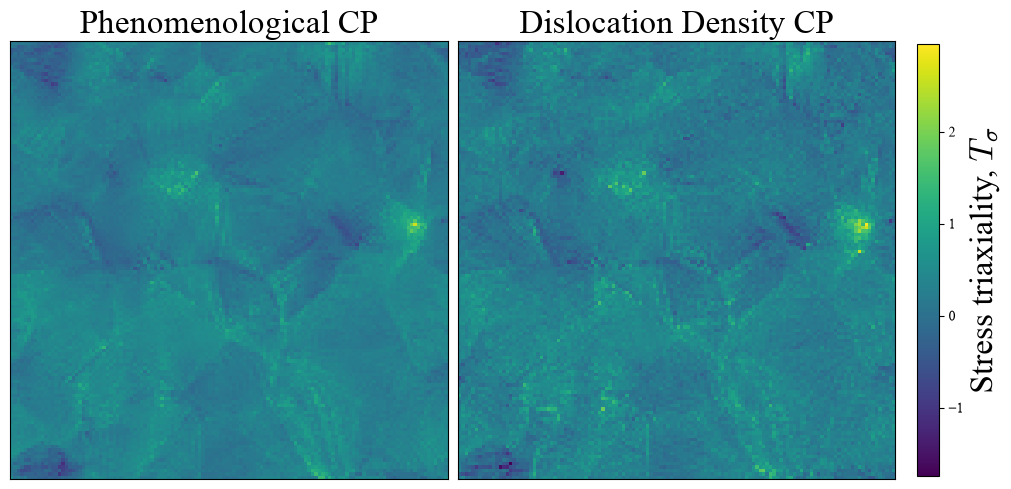

In [166]:
# Pheno max
CPanalysistools.comparison_map(np.flip(pheno_triax[:,:,70].transpose(), axis=0), 
                               np.flip(dislo_triax[:,:,70].transpose(), axis=0),
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'Stress triaxiality, $T_{\sigma}$',
                               #savefig = True,
                               #fig_name = "../figures/surface_stress_triaxiality_comparison_200_grains_128_VE_poster_label_size.png"
                               cbar_fontsize = 24, 
                               title_fontsize = 24)

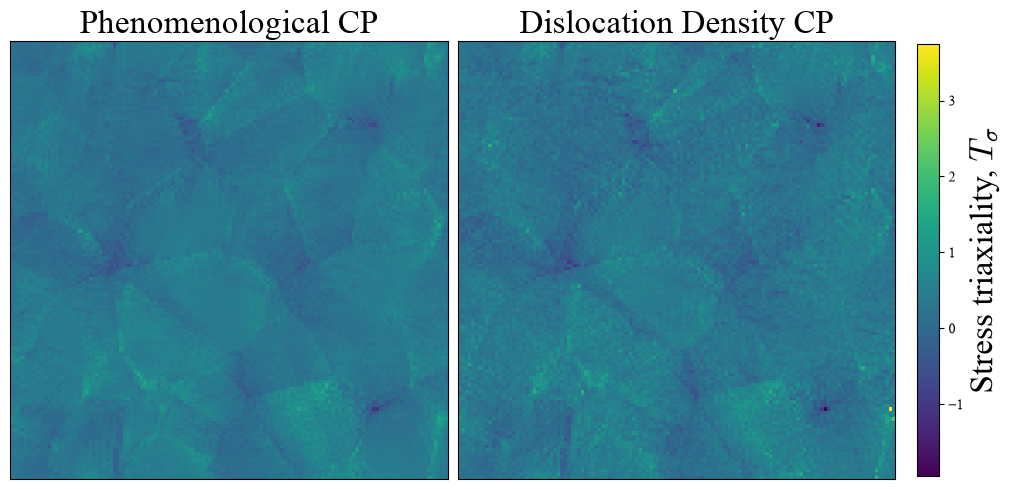

In [168]:
# Dislo max
CPanalysistools.comparison_map(np.flip(pheno_triax[:,:,79].transpose(), axis=0), 
                               np.flip(dislo_triax[:,:,79].transpose(), axis=0),
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'Stress triaxiality, $T_{\sigma}$',
                               #savefig = True,
                               #fig_name = "../figures/surface_stress_triaxiality_comparison_200_grains_128_VE_poster_label_size.png"
                               cbar_fontsize = 24, 
                               title_fontsize = 24)

Statistical comparison

In [8]:
CPanalysistools.statistical_comparison_metrics(pheno_triax, dislo_triax)

NRMSE (val 1 normalised): 0.504 
NRMSE (val 2 normalised): 0.496 
SSIM: 0.721 
Correlation coefficient: 0.772


### Strain component parallel to loading direction, $\varepsilon_{xx}$

In [5]:
pheno_xx_strain = np.load("../data/strain/pheno_128_xx_strain_200_grains.npy")
dislo_xx_strain = np.load("../data/strain/dislo_128_xx_strain_200_grains.npy") 

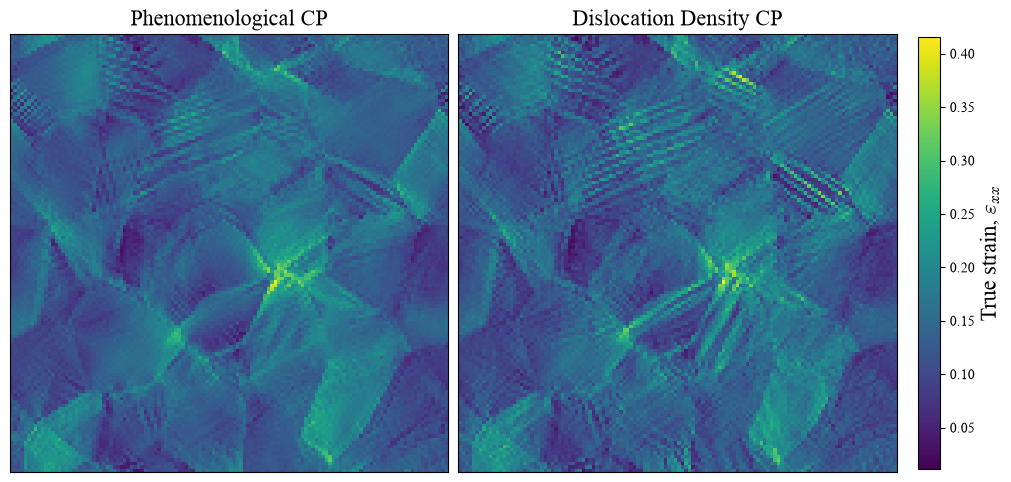

In [41]:
CPanalysistools.comparison_map(np.flip(pheno_xx_strain[:,:,0].transpose(), axis=0), 
                               np.flip(dislo_xx_strain[:,:,0].transpose(), axis=0),
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'True strain, $\varepsilon_{xx}$',
                               savefig = True,
                               fig_name = "surface_xx_strain_comparison_200_grains_128_VE.png")

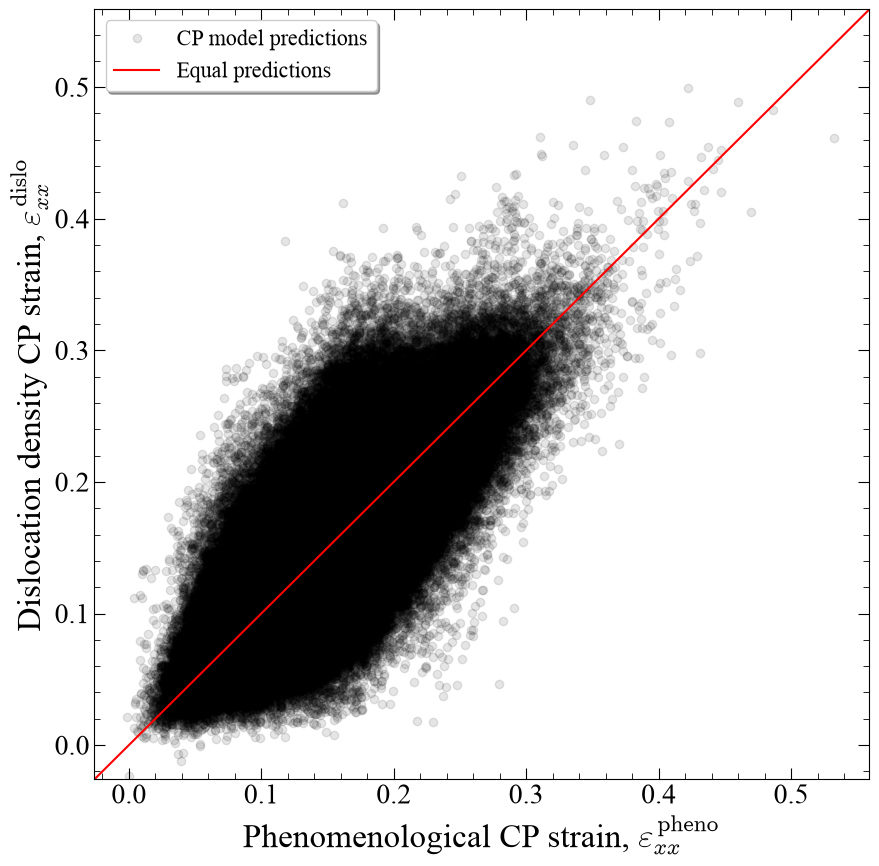

In [42]:
CPanalysistools.comparison_plot(pheno_xx_strain.flatten(order = 'F'), dislo_xx_strain.flatten(order = 'F'), 
                                r"Phenomenological CP strain, $\varepsilon_{xx}^{\text{pheno}}$",
                                r"Dislocation density CP strain, $\varepsilon_{xx}^{\text{dislo}}$",
                                savefig = True,
                                fig_name = "../figures/xx_strain_comparison_200_grains_128_VE.png")

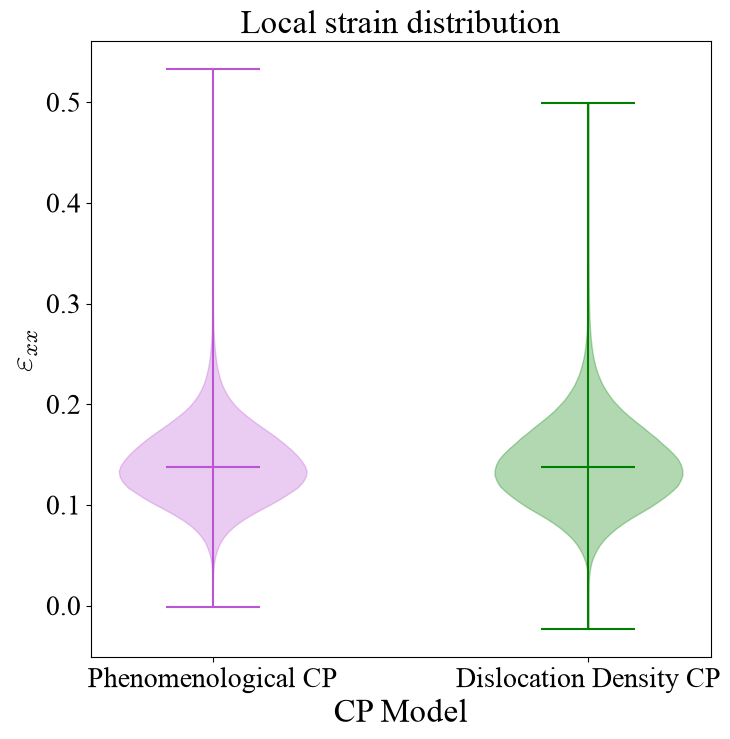

In [ ]:
CPanalysistools.comparison_violin_plot(pheno_xx_strain.flatten(order = 'F'), dislo_xx_strain.flatten(order = 'F'), 
                       "Phenomenological CP", 
                       "Dislocation Density CP", 
                       "Local strain distribution", 
                       r"$\varepsilon_{xx}$",
                       savefig = True,
                       fig_name = "../figures/xx_strain_violin_plot_200_grains_128_VE.png")

Statistical comparison

In [14]:
CPanalysistools.statistical_comparison_metrics(pheno_xx_strain, dislo_xx_strain)

NRMSE (val 1 normalised): 0.174 
NRMSE (val 2 normalised): 0.174 
SSIM: 0.698 
Correlation coefficient: 0.814


### Equivalent von Mises strain

In [21]:
pheno_vM_strain = np.load("../data/vM_strains/pheno_vM_strain_200_grains.npy")
dislo_vM_strain = np.load("../data/vM_strains/dislo_vM_strain_200_grains.npy") 

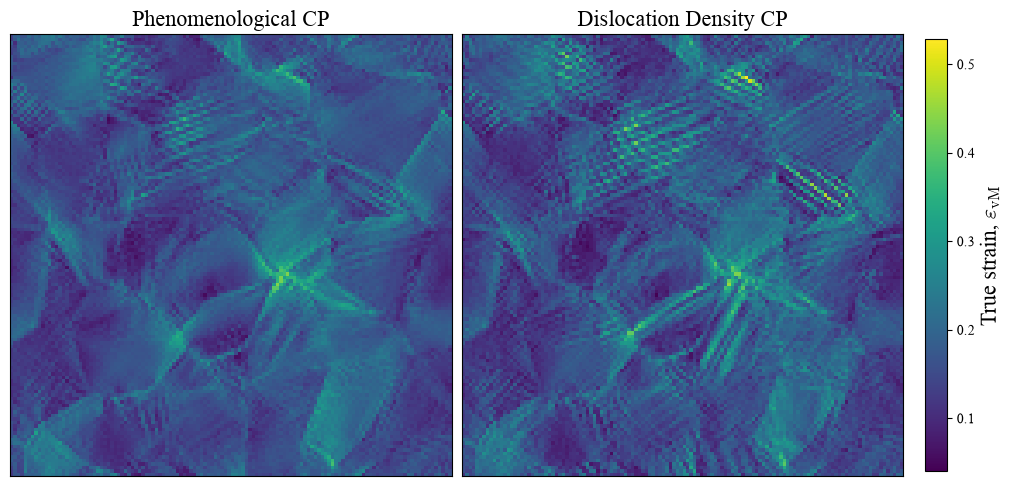

In [46]:
CPanalysistools.comparison_map(np.flip(pheno_vM_strain[:,:,0].transpose(), axis=0), 
                               np.flip(dislo_vM_strain[:,:,0].transpose(), axis=0),
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'True strain, $\varepsilon_{\text{vM}}$',
                               savefig = True,
                               fig_name = "../figures/surface_vM_equiv_strain_comparison_200_grains_128_VE.png")

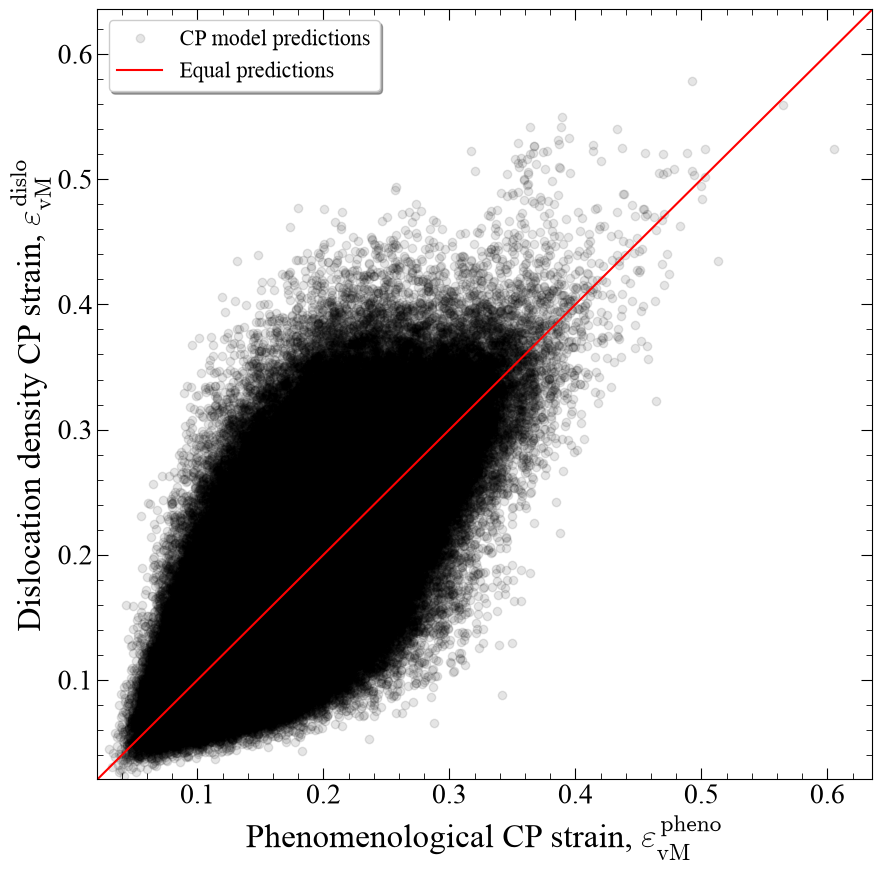

In [47]:
CPanalysistools.comparison_plot(pheno_vM_strain.flatten(order = 'F'), dislo_vM_strain.flatten(order = 'F'), 
                                r"Phenomenological CP strain, $\varepsilon_{\text{vM}}^{\text{pheno}}$",
                                r"Dislocation density CP strain, $\varepsilon_{\text{vM}}^{\text{dislo}}$",
                                savefig = True,
                                fig_name = "../figures/equiv_vM_strain_comparison_200_grains_128_VE.png")

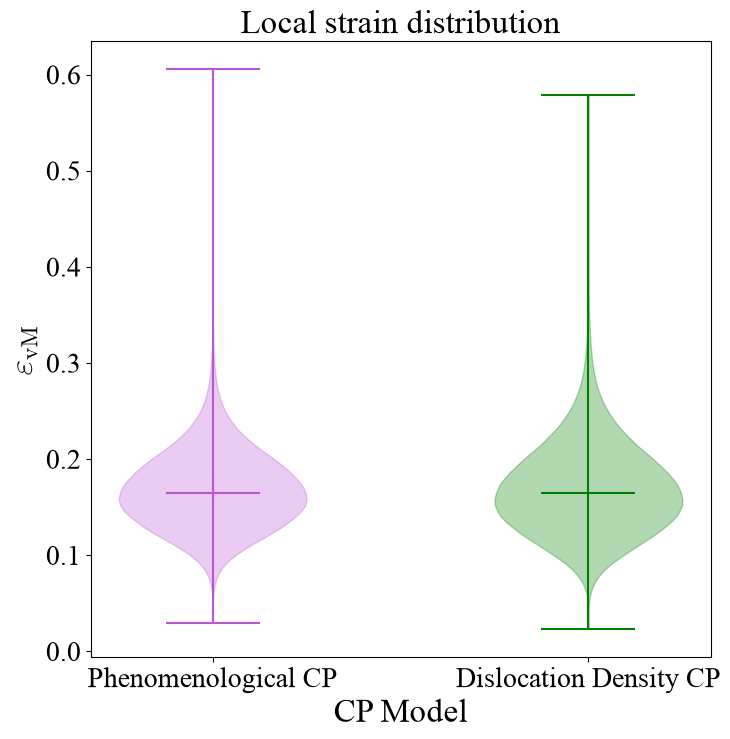

In [48]:
CPanalysistools.comparison_violin_plot(pheno_vM_strain.flatten(order = 'F'), dislo_vM_strain.flatten(order = 'F'), 
                       "Phenomenological CP", 
                       "Dislocation Density CP", 
                       "Local strain distribution", 
                       r"$\varepsilon_{\text{vM}}$",
                       savefig = True,
                       fig_name = "../figures/equiv_vM_strain_violin_plot_200_grains_128_VE.png")

### Comparison of max $\varepsilon_{\text{vM}}$

In [84]:
pheno_max_vM_strain_idx = np.where(pheno_vM_strain == max(pheno_vM_strain.flatten()))
dislo_max_vM_strain_idx = np.where(dislo_vM_strain == max(dislo_vM_strain.flatten()))
pheno_max_vM_strain_idx, dislo_max_vM_strain_idx

((array([80]), array([57]), array([2])),
 (array([108]), array([107]), array([76])))

In [89]:
vM_min_pheno_max = min(min(value) for value in (pheno_vM_strain[:,:,pheno_max_vM_strain_idx[-1]].flatten(), dislo_vM_strain[:,:,pheno_max_vM_strain_idx[-1]].flatten()))
vM_max_pheno_max = max(max(value) for value in (pheno_vM_strain[:,:,pheno_max_vM_strain_idx[-1]].flatten(), dislo_vM_strain[:,:,pheno_max_vM_strain_idx[-1]].flatten()))

vM_min_dislo_max = min(min(value) for value in (pheno_vM_strain[:,:,dislo_max_vM_strain_idx[-1]].flatten(), dislo_vM_strain[:,:,dislo_max_vM_strain_idx[-1]].flatten()))
vM_max_dislo_max = max(max(value) for value in (pheno_vM_strain[:,:,dislo_max_vM_strain_idx[-1]].flatten(), dislo_vM_strain[:,:,dislo_max_vM_strain_idx[-1]].flatten()))

In [98]:
pheno_max_vM_strain_idx[-1][0]

np.int64(2)

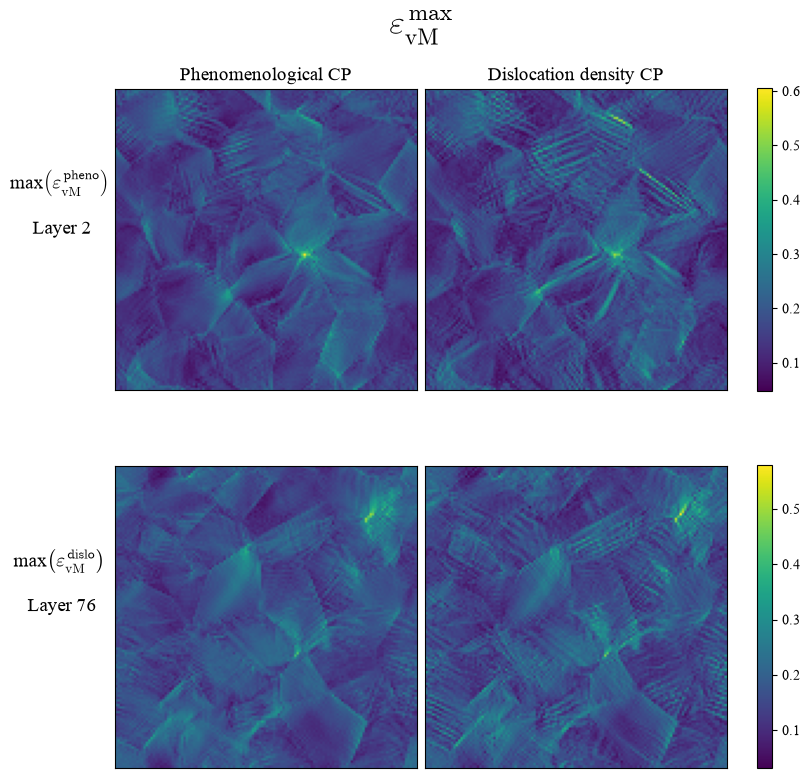

In [144]:
fig_max_vM_strain_comp, ax_max_vM_strain_comp = plt.subplots(2,2, figsize = (8,8), constrained_layout = True)

fig_max_vM_strain_comp.suptitle(r"$\varepsilon^{\text{max}}_{\text{vM}}$", x = 0.52, math_fontfamily = 'cm', fontsize = 24)
ax_max_vM_strain_comp[0,0].set_title("Phenomenological CP", fontsize = 14)
ax_max_vM_strain_comp[0,1].set_title("Dislocation density CP", fontsize = 14)
im_pheno_pheno_max = ax_max_vM_strain_comp[0,0].imshow(np.flip(pheno_vM_strain[:,:,pheno_max_vM_strain_idx[-1][0]].transpose(), axis=0), vmin = vM_min_pheno_max, vmax = vM_max_pheno_max)
im_pheno_dislo_max = ax_max_vM_strain_comp[1,0].imshow(np.flip(pheno_vM_strain[:,:,dislo_max_vM_strain_idx[-1][0]].transpose(), axis=0), vmin = vM_min_dislo_max, vmax = vM_max_dislo_max)
im_dislo_pheno_max = ax_max_vM_strain_comp[0,1].imshow(np.flip(dislo_vM_strain[:,:,pheno_max_vM_strain_idx[-1][0]].transpose(), axis = 0), vmin = vM_min_pheno_max, vmax = vM_max_pheno_max)
im_dislo_dislo_max = ax_max_vM_strain_comp[1,1].imshow(np.flip(dislo_vM_strain[:,:,dislo_max_vM_strain_idx[-1][0]].transpose(), axis = 0), vmin = vM_min_dislo_max, vmax = vM_max_dislo_max)

vM_strain_cbar_dislo_pheno_max = fig_max_vM_strain_comp.colorbar(im_dislo_pheno_max, ax=ax_max_vM_strain_comp[0,:], orientation = 'vertical', shrink = 0.82)
vM_strain_cbar_dislo_dislo_max = fig_max_vM_strain_comp.colorbar(im_dislo_dislo_max, ax=ax_max_vM_strain_comp[1,:], orientation = 'vertical', shrink = 0.82)

vM_strain_cbar_dislo_pheno_max.set_label(label = None, rotation = 90, fontsize = 16, math_fontfamily = 'cm')
vM_strain_cbar_dislo_dislo_max.set_label(label = None, rotation = 90, fontsize = 16, math_fontfamily = 'cm')

ax_max_vM_strain_comp[0,0].set_ylabel(r"max$\left(\varepsilon^{\text{pheno}}_{\text{vM}}\right)$"f"\n \n Layer {pheno_max_vM_strain_idx[-1][0]}", math_fontfamily = "cm", rotation = 0, fontsize = 14, labelpad = 40)
ax_max_vM_strain_comp[1,0].set_ylabel(r"max$\left(\varepsilon^{\text{dislo}}_{\text{vM}}\right)$"f"\n \n Layer {dislo_max_vM_strain_idx[-1][0]}", math_fontfamily = "cm", rotation = 0, fontsize = 14, labelpad = 40)

for i in range(2):
    ax_max_vM_strain_comp[i,0].set_xticks([])
    ax_max_vM_strain_comp[i,0].set_yticks([])
    ax_max_vM_strain_comp[i,1].set_xticks([])
    ax_max_vM_strain_comp[i,1].set_yticks([])

plt.savefig("../figures/max_val_comparisons/max_vM_strain_comparison.png", dpi = 800)

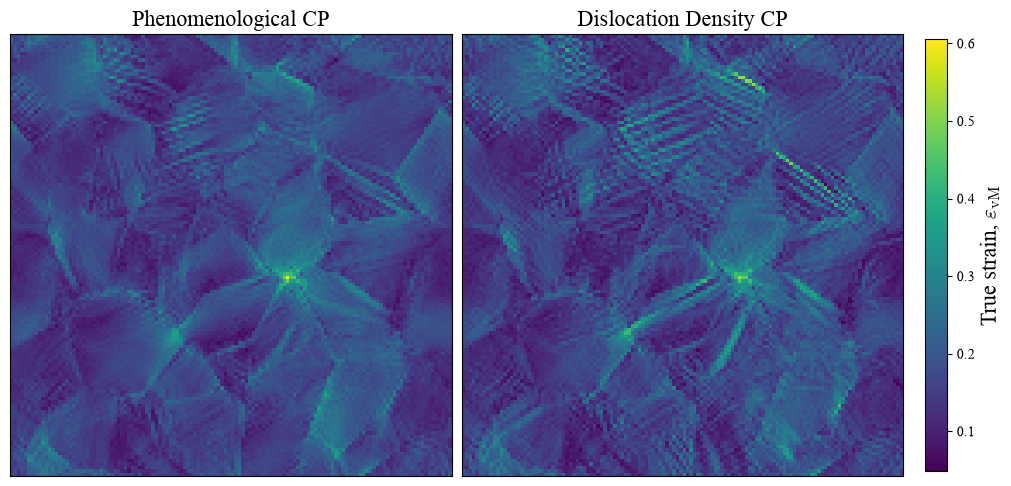

In [ ]:
# Pheno max
CPanalysistools.comparison_map(np.flip(pheno_vM_strain[:,:,2].transpose(), axis=0), 
                               np.flip(dislo_vM_strain[:,:,2].transpose(), axis=0),
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'von Mises strain, $\varepsilon_{\text{vM}}$')

In [ ]:
# Dislo max
CPanalysistools.comparison_map(np.flip(pheno_vM_strain[:,:,76].transpose(), axis=0), 
                               np.flip(dislo_vM_strain[:,:,76].transpose(), axis=0),
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'True strain, $\varepsilon_{\text{vM}}$',
                               )

TypeError: comparison_map() got an unexpected keyword argument 'cbar_ticks_fontsize'

Statistical comparison

In [49]:
CPanalysistools.statistical_comparison_metrics(pheno_vM_strain, dislo_vM_strain)

NRMSE (val 1 normalised): 0.184 
NRMSE (val 2 normalised): 0.183 
SSIM: 0.657 
Correlation coefficient: 0.769


### $r$-value and volume-averaged equivalent von Mises strains

In [7]:
pheno_r_vals = np.load("../data/r_value/pheno_r_vals_20_time_steps.npy")
dislo_r_vals = np.load("../data/r_value/dislo_r_vals_20_time_steps.npy")

In [8]:
pheno_equiv_vM_strain = np.load("../data/vM_strains/pheno_vM_strains_avg_20_time_steps.npy")
dislo_equiv_vM_strain = np.load("../data/vM_strains/dislo_vM_strains_avg_20_time_steps.npy")

(0.85, 0.86)

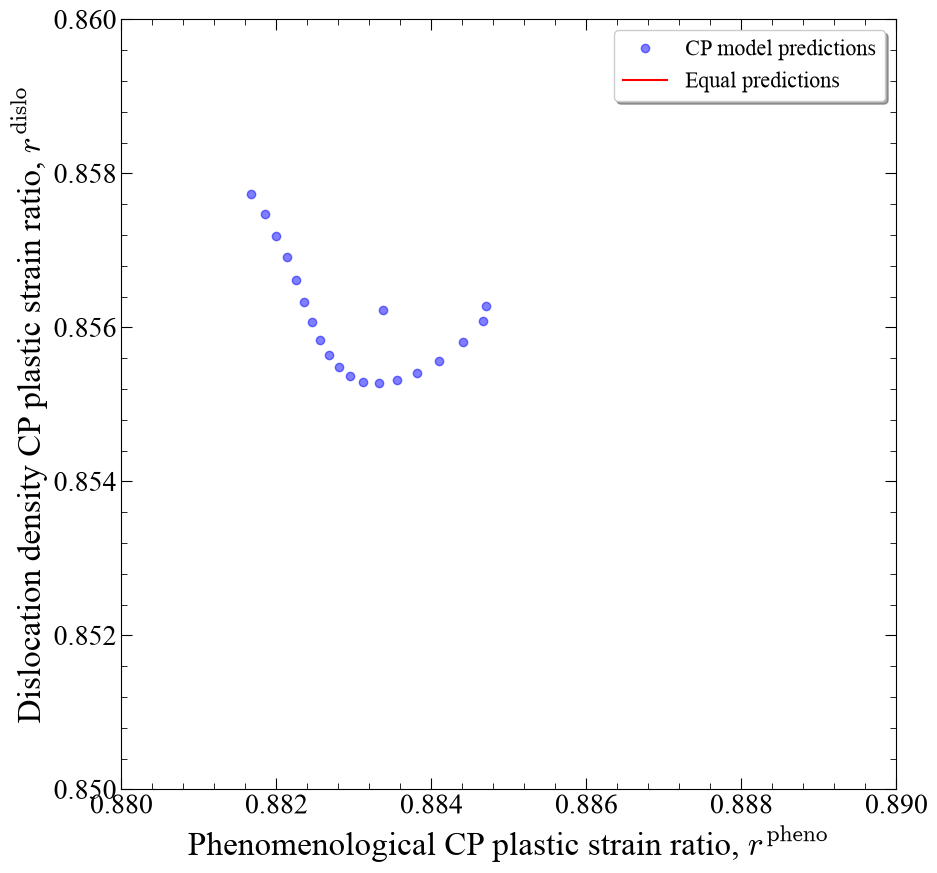

In [11]:
%matplotlib inline
CPanalysistools.comparison_plot(pheno_r_vals[1:], 
                                dislo_r_vals[1:],
                                r"Phenomenological CP plastic strain ratio, $r^{\text{pheno}}$",
                                r"Dislocation density CP plastic strain ratio, $r^{\text{dislo}}$")
#plt.xlim(min(min(pheno_r_vals[1:]), min(dislo_r_vals[1:])), max(max(pheno_r_vals[1:]), max(dislo_r_vals[1:])))
plt.xlim(0.88, 0.89)
plt.ylim(0.85, 0.86)
#plt.ylim(min(min(pheno_r_vals[1:]), min(dislo_r_vals[1:])), max(max(pheno_r_vals[1:]), max(dislo_r_vals[1:])))

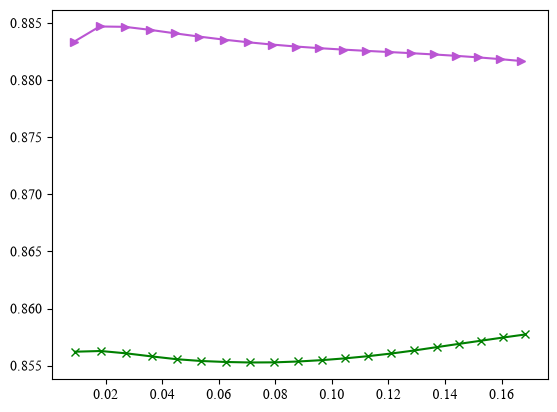

In [12]:
plt.plot(pheno_equiv_vM_strain[1:], pheno_r_vals[1:],  color = 'mediumorchid', marker = ">")
plt.plot(dislo_equiv_vM_strain[1:], dislo_r_vals[1:], color = 'green', marker = "x")
#plt.ylim(0,1)

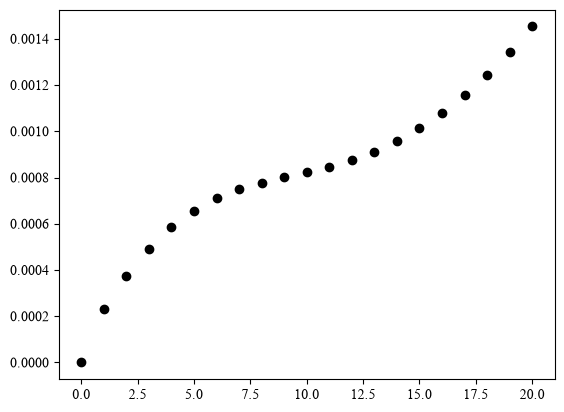

In [20]:
plt.plot(np.linspace(0,20,21), np.abs(pheno_equiv_vM_strain - dislo_equiv_vM_strain), 'ko')
#plt.axline([0,0], slope = 1, color = 'r', label = 'Equal predictions')
#plt.legend()

In [19]:
pheno_equiv_vM_strain[-1], dislo_equiv_vM_strain[-1]

(np.float64(0.16690788017082497), np.float64(0.1683610650293248))

Some plots showing larger strains for dislocation model could be biased by global vM strain being larger for dislocation density simulations than phenomenological for a given time step.

### Accumulated plastic strain energy density

In [22]:
pheno_mat_file = "./phenopowerlaw/phenopowerlaw_128_rolled_copper_200_grains_5k_time_steps_2026-08-28_104710/execute/t_1/material.yaml"
dislo_mat_file = "./dislo_density/dislotwin_128_rolled_copper_200_grains_5k_time_steps_2026-08-28_104634/execute/t_1/material.yaml"

In [4]:
%%time
extract_data = CPanalysistools.extractDAMASKdata()
pheno_psed_arrs, pheno_apsed = extract_data.extract_accum_plastic_strain_energy_density(damask_file = pheno_file, 
                                                                       mat_file = pheno_mat_file, 
                                                                       rve_shape = [128,128,128])

100%|██████████| 101/101 [04:58<00:00,  2.96s/it]


CPU times: user 3min 14s, sys: 1min 35s, total: 4min 49s
Wall time: 5min 7s


In [5]:
np.save("pheno_128_psed_per_inc_200_grains.npy", pheno_psed_arrs)
np.save("pheno_128_apsed_200_grains.npy", pheno_apsed)

In [10]:
pheno_psed_arrs.shape, pheno_apsed.shape

((101, 128, 128, 128), (128, 128, 128))

In [11]:
dislo_psed_arrs, dislo_apsed = extract_data.extract_accum_plastic_strain_energy_density(damask_file = dislo_file, 
                                                                       mat_file = dislo_mat_file, 
                                                                       rve_shape = [128,128,128])

100%|██████████| 101/101 [06:17<00:00,  3.74s/it]


In [12]:
np.save("dislo_128_psed_per_inc_200_grains.npy", dislo_psed_arrs)
np.save("dislo_128_apsed_200_grains.npy", dislo_apsed)

In [23]:
#pheno_psed_arrs = np.load("pheno_128_psed_per_inc_200_grains.npy")
pheno_apsed = np.load("../data/accumulated_plastic_work/pheno_128_apsed_200_grains.npy")
#dislo_psed_arrs = np.load("dislo_128_psed_per_inc_200_grains.npy")
dislo_apsed = np.load("../data/accumulated_plastic_work/dislo_128_apsed_200_grains.npy")

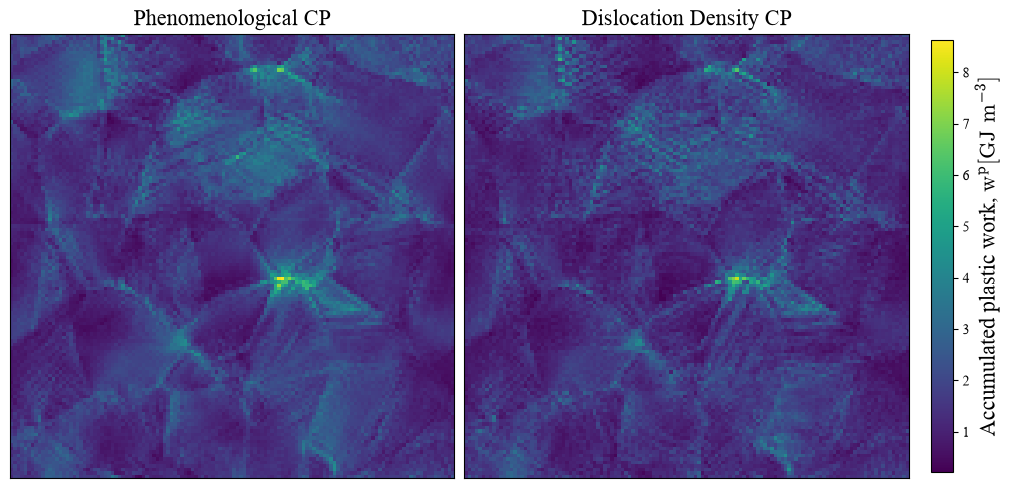

In [12]:
%matplotlib inline
CPanalysistools.comparison_map(np.flip(pheno_apsed[:,:,0].transpose(), axis=0)*1e-9, 
                               np.flip(dislo_apsed[:,:,0].transpose(), axis=0)*1e-9,
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'Accumulated plastic work, $\text{w}^{\text{p}} [\text{GJ m}^{-3}]$',
                               savefig = True,
                               fig_name = "../figures/surface_APSED_comparison_200_grains_128_VE_GJ.png")

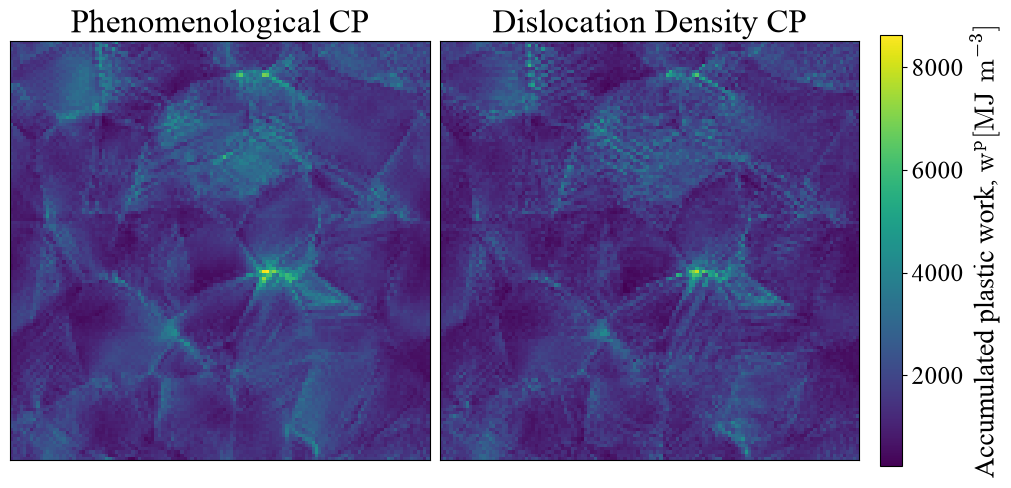

In [ ]:
comparison_map(np.flip(pheno_apsed[:,:,0].transpose(), axis=0)*1e-6, 
                               np.flip(dislo_apsed[:,:,0].transpose(), axis=0)*1e-6,
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'Accumulated plastic work, $\text{w}^{\text{p}} [\text{MJ m}^{-3}]$',
                               savefig = True,
                               fig_name = "../figures/surface_APSED_comparison_200_grains_128_VE_GJ.png",
                               cbar_fontsize = 20,
                               cbar_ticks_fontsize = 18, 
                               title_fontsize = 24)

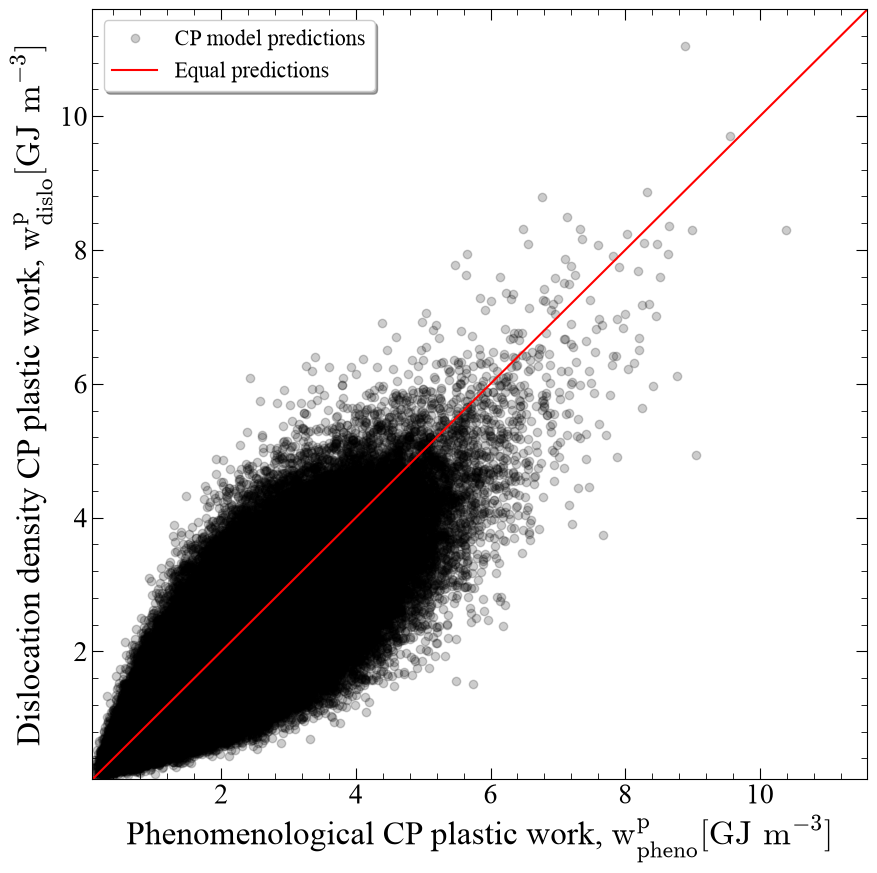

In [17]:
%matplotlib inline
CPanalysistools.comparison_plot(pheno_apsed.flatten(order = 'F')*1e-9, dislo_apsed.flatten(order = 'F')*1e-9, 
                                r"Phenomenological CP plastic work, $\text{w}^{\text{p}}_{\text{pheno}} [\text{GJ m}^{-3}]$",
                                r"Dislocation density CP plastic work, $\text{w}^{\text{p}}_{\text{dislo}} [\text{GJ m}^{-3}]$",
                                marker_color = 'k',
                                marker_transparency = 0.2,
                                savefig = True,
                                fig_name = "../figures/APSED_comparison_200_grains_128_VE_GJ.png")

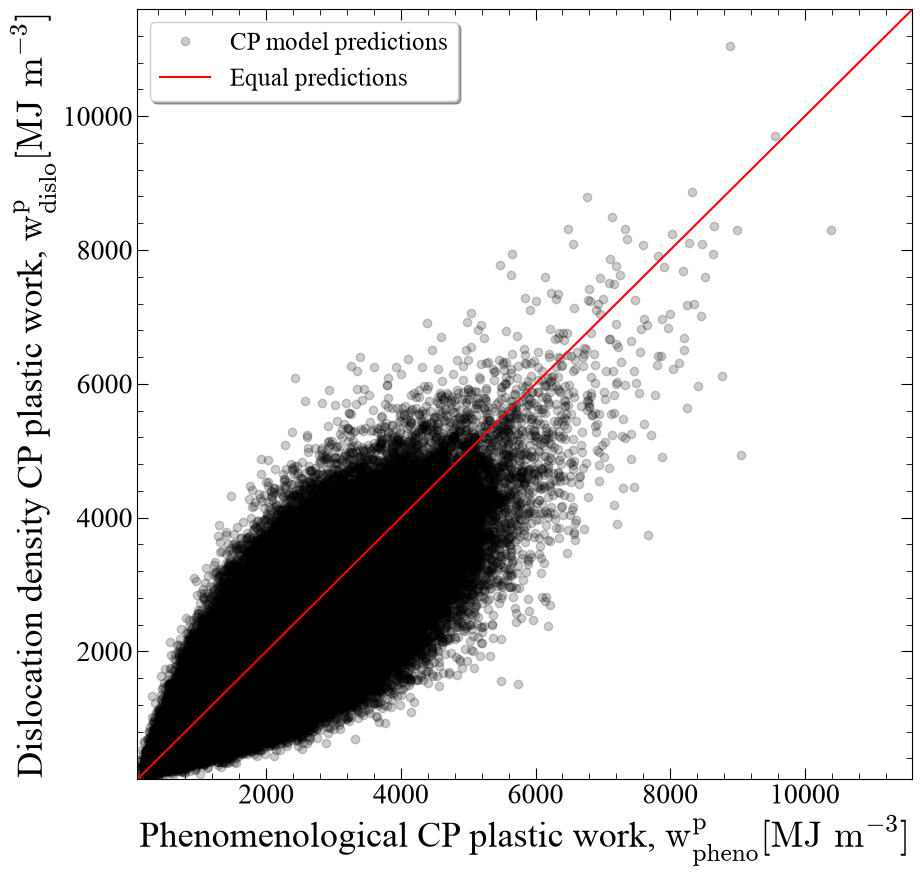

In [62]:
comparison_plot(pheno_apsed.flatten(order = 'F')*1e-6, dislo_apsed.flatten(order = 'F')*1e-6, 
                                r"Phenomenological CP plastic work, $\text{w}^{\text{p}}_{\text{pheno}} [\text{MJ m}^{-3}]$",
                                r"Dislocation density CP plastic work, $\text{w}^{\text{p}}_{\text{dislo}} [\text{MJ m}^{-3}]$",
                                marker_color = 'k',
                                legend_label = 'CP model predictions',
                                marker_transparency = 0.2,
                                axis_label_fontsize = 26,
                                tick_label_fontsize = 20,
                                legend_fontsize = 18,
                                savefig = True,
                                fig_name = "../figures/APSED_comparison_200_grains_128_VE_poster_label_size.png"
                                )       


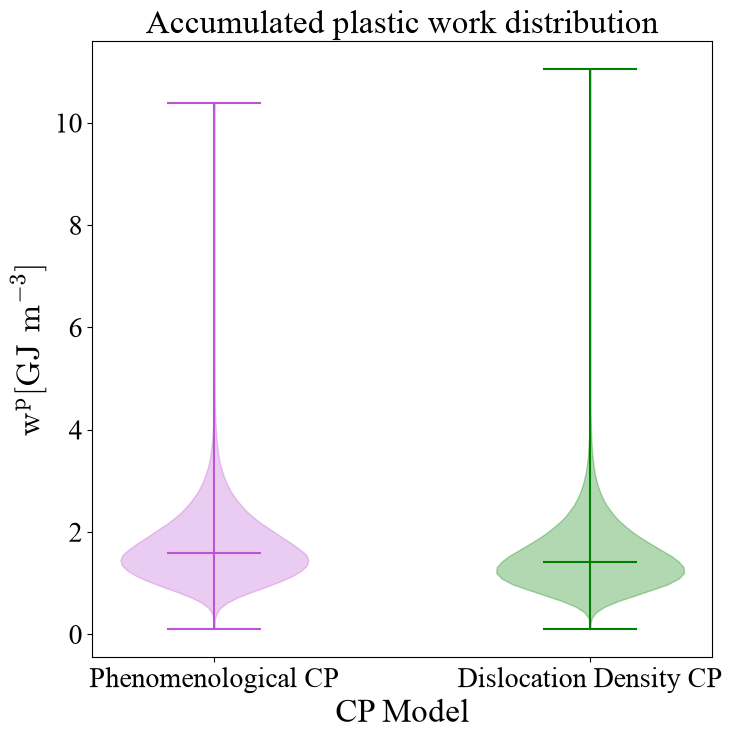

In [14]:
%matplotlib inline
CPanalysistools.comparison_violin_plot(pheno_apsed.flatten(order = 'F')*1e-9, dislo_apsed.flatten(order = 'F')*1e-9, 
                       "Phenomenological CP", 
                       "Dislocation Density CP", 
                       "Accumulated plastic work distribution", 
                       r"$\text{w}^{\text{p}} [\text{GJ m}^{-3}]$",
                       savefig = True,
                       fig_name = "../figures/APSED_violin_plot_200_grains_128_VE_GJ.png")

### Comparison of max $\text{w}^{\text{p}}$

In [81]:
pheno_max_apsed_idx = np.where(pheno_apsed == max(pheno_apsed.flatten()))
dislo_max_apsed_idx = np.where(dislo_apsed == max(dislo_apsed.flatten()))
pheno_max_apsed_idx, dislo_max_apsed_idx

((array([86]), array([9]), array([32])),
 (array([110]), array([108]), array([77])))

In [187]:
apsed_min_pheno_max = min(min(value) for value in (pheno_apsed[:,:,pheno_max_apsed_idx[-1][0]].flatten()*1e-9, dislo_apsed[:,:,pheno_max_apsed_idx[-1][0]].flatten()*1e-9))
apsed_max_pheno_max = max(max(value) for value in (pheno_apsed[:,:,pheno_max_apsed_idx[-1][0]].flatten()*1e-9, dislo_apsed[:,:,pheno_max_apsed_idx[-1][0]].flatten()*1e-9))

apsed_min_dislo_max = min(min(value) for value in (pheno_apsed[:,:,dislo_max_apsed_idx[-1][0]].flatten()*1e-9, dislo_apsed[:,:,dislo_max_apsed_idx[-1][0]].flatten()*1e-9))
apsed_max_dislo_max = max(max(value) for value in (pheno_apsed[:,:,dislo_max_apsed_idx[-1][0]].flatten()*1e-9, dislo_apsed[:,:,dislo_max_apsed_idx[-1][0]].flatten()*1e-9))

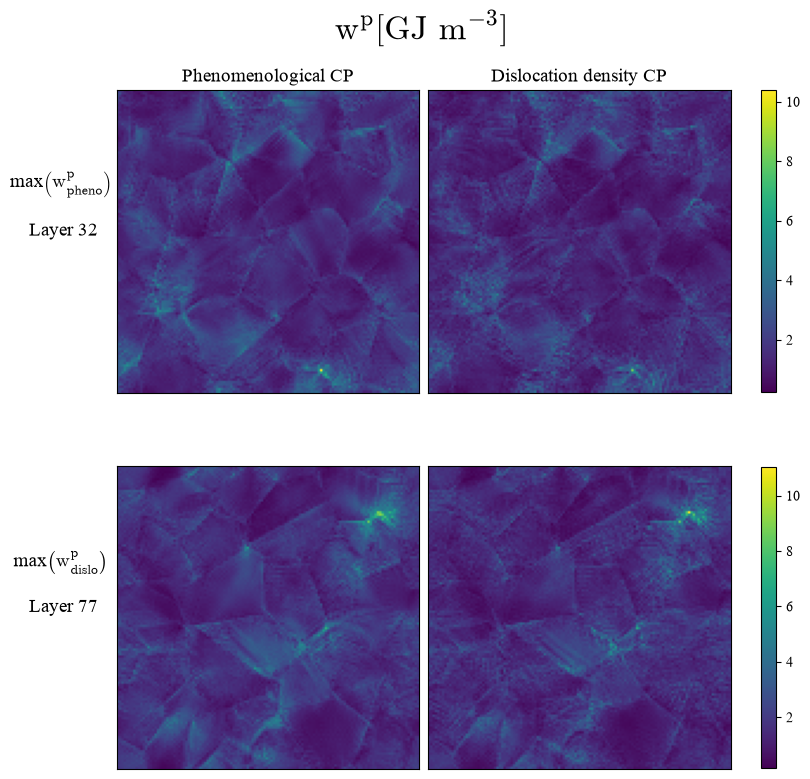

In [189]:
fig_max_apsed_comp, ax_max_apsed_comp = plt.subplots(2,2, figsize = (8,8), constrained_layout = True)

fig_max_apsed_comp.suptitle(r"$\text{w}^{\text{p}} [\text{GJ m}^{-3}]$", x = 0.52, math_fontfamily = 'cm', fontsize = 24)
ax_max_apsed_comp[0,0].set_title("Phenomenological CP", fontsize = 14)
ax_max_apsed_comp[0,1].set_title("Dislocation density CP", fontsize = 14)
im_pheno_pheno_max_apsed = ax_max_apsed_comp[0,0].imshow(np.flip(pheno_apsed[:,:,pheno_max_apsed_idx[-1][0]].transpose(), axis=0)*1e-9, vmin = apsed_min_pheno_max, vmax = apsed_max_pheno_max)
im_pheno_dislo_max_apsed = ax_max_apsed_comp[1,0].imshow(np.flip(pheno_apsed[:,:,dislo_max_apsed_idx[-1][0]].transpose(), axis=0)*1e-9, vmin = apsed_min_dislo_max, vmax = apsed_max_dislo_max)
im_dislo_pheno_max_apsed = ax_max_apsed_comp[0,1].imshow(np.flip(dislo_apsed[:,:,pheno_max_apsed_idx[-1][0]].transpose(), axis = 0)*1e-9, vmin = apsed_min_pheno_max, vmax = apsed_max_pheno_max)
im_dislo_dislo_max_apsed = ax_max_apsed_comp[1,1].imshow(np.flip(dislo_apsed[:,:,dislo_max_apsed_idx[-1][0]].transpose(), axis = 0)*1e-9, vmin = apsed_min_dislo_max, vmax = apsed_max_dislo_max)

apsed_cbar_dislo_pheno_max = fig_max_apsed_comp.colorbar(im_dislo_pheno_max_apsed, ax=ax_max_apsed_comp[0,:], orientation = 'vertical', shrink = 0.82)
apsed_cbar_dislo_dislo_max = fig_max_apsed_comp.colorbar(im_dislo_dislo_max_apsed, ax=ax_max_apsed_comp[1,:], orientation = 'vertical', shrink = 0.82)

apsed_cbar_dislo_pheno_max.set_label(label = None, rotation = 90, fontsize = 16, math_fontfamily = 'cm')
apsed_cbar_dislo_dislo_max.set_label(label = None, rotation = 90, fontsize = 16, math_fontfamily = 'cm')

ax_max_apsed_comp[0,0].set_ylabel(r"max$\left(\text{w}^{\text{p}}_{\text{pheno}}\right)$"f"\n \n Layer {pheno_max_apsed_idx[-1][0]}", math_fontfamily = "cm", rotation = 0, fontsize = 14, labelpad = 40)
ax_max_apsed_comp[1,0].set_ylabel(r"max$\left(\text{w}^{\text{p}}_{\text{dislo}}\right)$"f"\n \n Layer {dislo_max_apsed_idx[-1][0]}", math_fontfamily = "cm", rotation = 0, fontsize = 14, labelpad = 40)

for i in range(2):
    ax_max_apsed_comp[i,0].set_xticks([])
    ax_max_apsed_comp[i,0].set_yticks([])
    ax_max_apsed_comp[i,1].set_xticks([])
    ax_max_apsed_comp[i,1].set_yticks([])

plt.savefig("../figures/max_val_comparisons/max_APSED_comparison.png", dpi = 800)

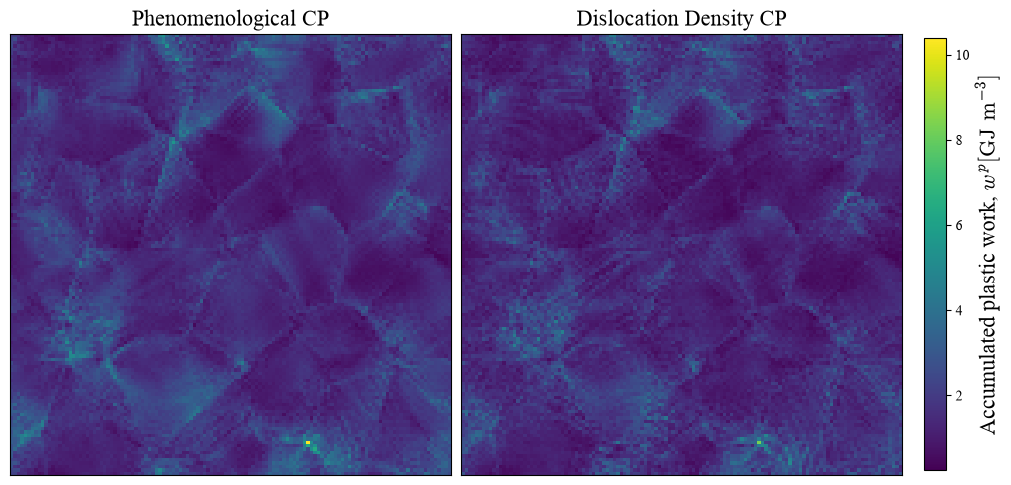

In [82]:
# Pheno max
CPanalysistools.comparison_map(np.flip(pheno_apsed[:,:,32].transpose(), axis=0)*1e-9, 
                               np.flip(dislo_apsed[:,:,32].transpose(), axis=0)*1e-9,
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'Accumulated plastic work, $w^p [\text{GJ m}^{-3}]$')

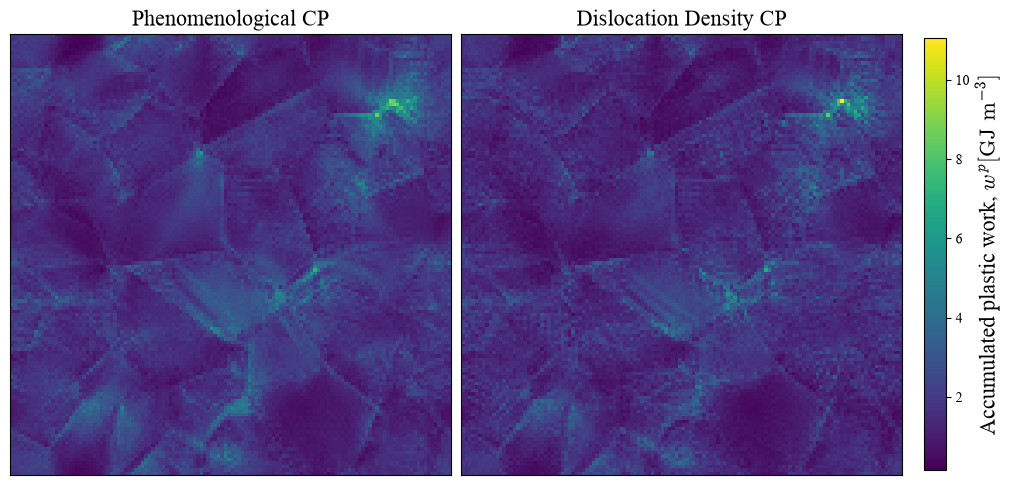

In [83]:
# Dislo max
CPanalysistools.comparison_map(np.flip(pheno_apsed[:,:,77].transpose(), axis=0)*1e-9, 
                               np.flip(dislo_apsed[:,:,77].transpose(), axis=0)*1e-9,
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'Accumulated plastic work, $w^p [\text{GJ m}^{-3}]$')

Statistical comparison

In [7]:
CPanalysistools.statistical_comparison_metrics(pheno_apsed, dislo_apsed)

NRMSE (val 1 normalised): 0.242 
NRMSE (val 2 normalised): 0.271 
SSIM: 0.757 
Correlation coefficient: 0.832


Investigating maximum APSED

In [26]:
np.unravel_index(np.argmax(pheno_apsed.flatten(order = 'F')), pheno_apsed.shape, order = 'F'), np.unravel_index(np.argmax(dislo_apsed.flatten(order = 'F')), dislo_apsed.shape, order = 'F')

((np.int64(86), np.int64(9), np.int64(32)),
 (np.int64(110), np.int64(108), np.int64(77)))

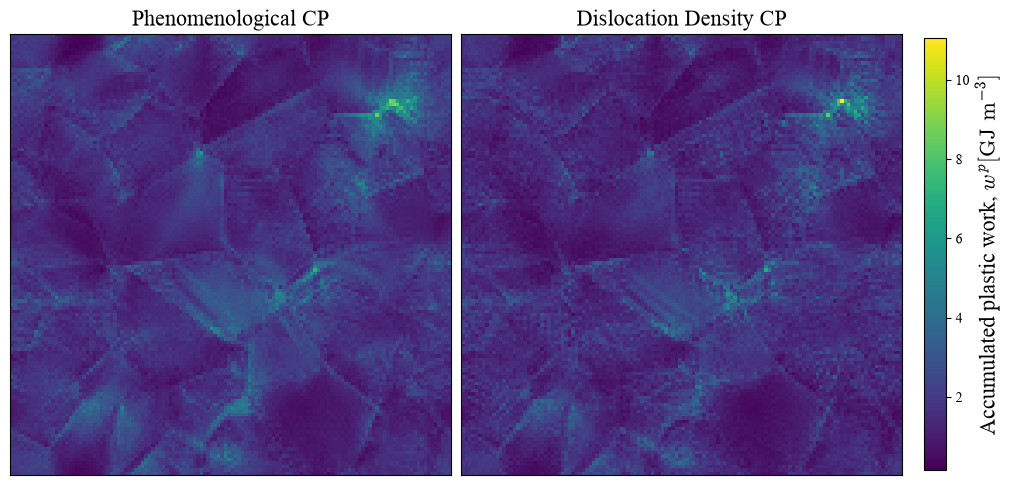

In [27]:
CPanalysistools.comparison_map(np.flip(pheno_apsed[:,:,77].transpose(), axis=0)*1e-9, 
                               np.flip(dislo_apsed[:,:,77].transpose(), axis=0)*1e-9,
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'Accumulated plastic work, $w^p [\text{GJ m}^{-3}]$')

### PSED over different increments

In [62]:
pheno_psed_arrs.shape

(101, 128, 128, 128)

In [ ]:
# Extract SSIM for plastic work accumulated at each time step
psed_ssim_vals = []
for i in tqdm(range(len(pheno_psed_arrs))):
    max_val = max(max(pheno_psed_arrs[i].flatten(order='F')), max(dislo_psed_arrs[i].flatten(order='F')))
    min_val = min(min(pheno_psed_arrs[i].flatten(order='F')), min(dislo_psed_arrs[i].flatten(order='F')))
    psed_ssim = skimage.metrics.structural_similarity(pheno_psed_arrs[i], dislo_psed_arrs[i], data_range = max_val - min_val)
    psed_ssim_vals.append(psed_ssim)

  0%|          | 0/101 [00:00<?, ?it/s]/mnt/iusers01/jf01/j38714mw/matflow_v40a7-venv/lib/python3.13/site-packages/skimage/metrics/_structural_similarity.py:269: RuntimeWarning: invalid value encountered in divide
  S = (A1 * A2) / D
100%|██████████| 101/101 [02:20<00:00,  1.39s/it]


In [69]:
apsed_ssim_vals = []
i=0
pheno_apsed_inc = pheno_psed_arrs[0]
dislo_apsed_inc = dislo_psed_arrs[0]
while i < len(pheno_psed_arrs):
    if i > 0:
        pheno_apsed_inc = pheno_apsed_inc + pheno_psed_arrs[i]
        dislo_apsed_inc = dislo_apsed_inc + dislo_psed_arrs[i]

    max_val = max(max(pheno_apsed_inc.flatten(order='F')), max(dislo_apsed_inc.flatten(order='F')))
    min_val = min(min(pheno_apsed_inc.flatten(order='F')), min(dislo_apsed_inc.flatten(order='F')))
    apsed_ssim = skimage.metrics.structural_similarity(pheno_apsed_inc, dislo_apsed_inc, data_range = max_val - min_val)
    apsed_ssim_vals.append(apsed_ssim)
    pheno_apsed
    i+=1

/mnt/iusers01/jf01/j38714mw/matflow_v40a7-venv/lib/python3.13/site-packages/skimage/metrics/_structural_similarity.py:269: RuntimeWarning: invalid value encountered in divide
  S = (A1 * A2) / D


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: 

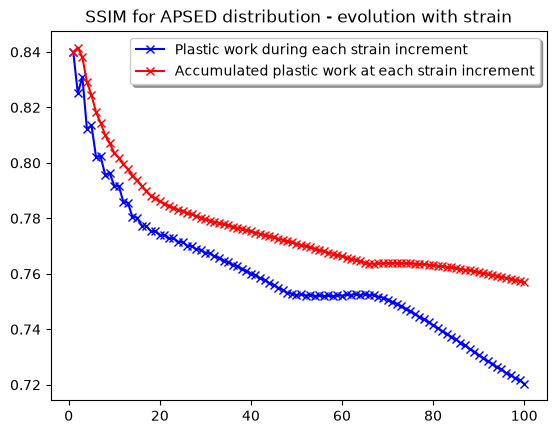

In [72]:
# This plots the similarity between the plastic work accumulated during each time step
plt.plot(np.linspace(0,100,101), psed_ssim_vals, color = 'blue', marker = "x", label = "Plastic work during each strain increment")
# This plots the accumulated plastic work at each time step
plt.plot(np.linspace(0,100,101), apsed_ssim_vals, color = 'red', marker = "x", label = "Accumulated plastic work at each strain increment")
plt.title("SSIM for APSED distribution - evolution with strain")
plt.legend(shadow = True)

### Maximum values per grain ID

In [9]:
material_IDs = np.load("../data/material_IDs_200_grains_128_cubed_VE.npy")

Stress triaxiality

In [7]:
max_pheno_triax_from_grains = CPanalysistools.max_val_from_grains(pheno_triax, material_IDs, 200)
max_dislo_triax_from_grains = CPanalysistools.max_val_from_grains(dislo_triax, material_IDs, 200)

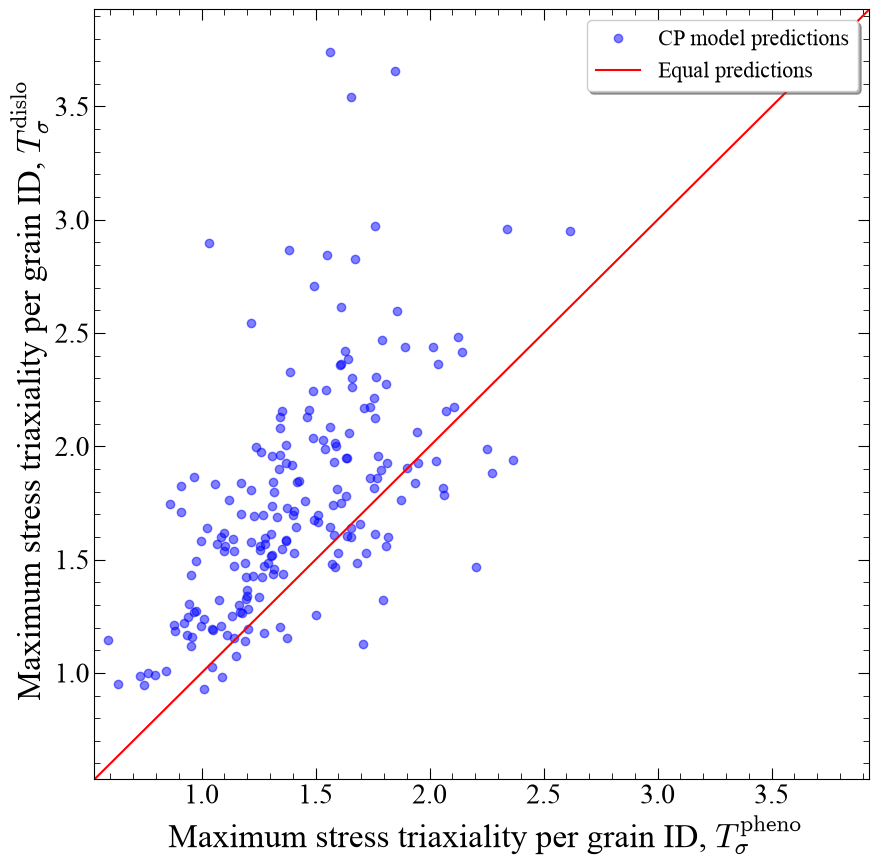

In [14]:
%matplotlib inline
CPanalysistools.comparison_plot(max_pheno_triax_from_grains, 
                                max_dislo_triax_from_grains, 
                                r" Maximum stress triaxiality per grain ID, $T_{\sigma}^{\text{pheno}}$", 
                                r" Maximum stress triaxiality per grain ID, $T_{\sigma}^{\text{dislo}}$",
                                savefig = True,
                                fig_name = "../figures/stress_triaxiality/max_stress_triaxiality_per_grain_200_grains_128_VE.png")
plt.legend(loc = 'upper right', shadow = True, fontsize = 16)

$\varepsilon_{xx}$ strain

In [16]:
max_pheno_xx_strain_from_grains = CPanalysistools.max_val_from_grains(pheno_xx_strain, material_IDs, 200)
max_dislo_xx_strain_from_grains = CPanalysistools.max_val_from_grains(dislo_xx_strain, material_IDs, 200)

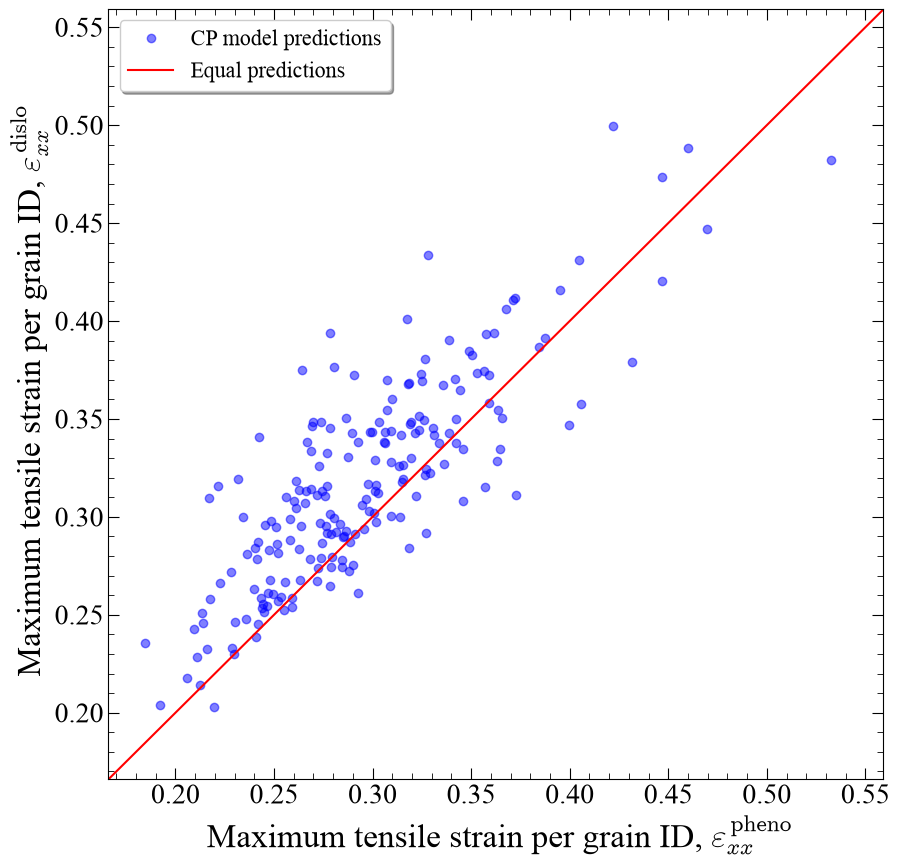

In [18]:
CPanalysistools.comparison_plot(max_pheno_xx_strain_from_grains, 
                                max_dislo_xx_strain_from_grains, 
                                r" Maximum tensile strain per grain ID, $\varepsilon_{xx}^{\text{pheno}}$", 
                                r" Maximum tensile strain per grain ID, $\varepsilon_{xx}^{\text{dislo}}$",
                                savefig = True,
                                fig_name = "../figures/xx_strain/max_xx_strain_per_grain_200_grains_128_VE.png")

vM strain

In [19]:
max_pheno_vM_strain_from_grains = CPanalysistools.max_val_from_grains(pheno_vM_strain, material_IDs, 200)
max_dislo_vM_strain_from_grains = CPanalysistools.max_val_from_grains(dislo_vM_strain, material_IDs, 200)

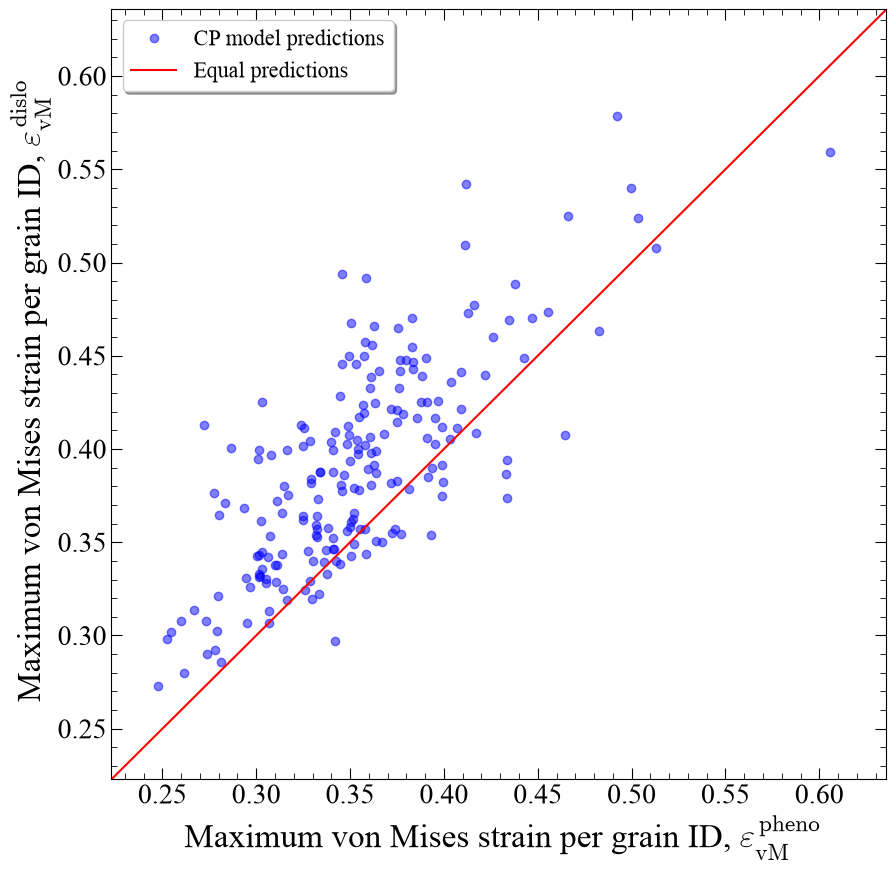

In [21]:
CPanalysistools.comparison_plot(max_pheno_vM_strain_from_grains, 
                                max_dislo_vM_strain_from_grains, 
                                r" Maximum von Mises strain per grain ID, $\varepsilon_{\text{vM}}^{\text{pheno}}$", 
                                r" Maximum von Mises strain per grain ID, $\varepsilon_{\text{vM}}^{\text{dislo}}$",
                                savefig = True,
                                fig_name = "../figures/vM_strain/max_equiv_vM_strain_per_grain_200_grains_128_VE.png")

APSED

In [22]:
max_pheno_apsed_from_grains = CPanalysistools.max_val_from_grains(pheno_apsed, material_IDs, 200)
max_dislo_apsed_from_grains = CPanalysistools.max_val_from_grains(dislo_apsed, material_IDs, 200)

In [23]:
max_pheno_apsed_from_grains = np.array(max_pheno_apsed_from_grains)*1e-6
max_dislo_apsed_from_grains = np.array(max_dislo_apsed_from_grains)*1e-6

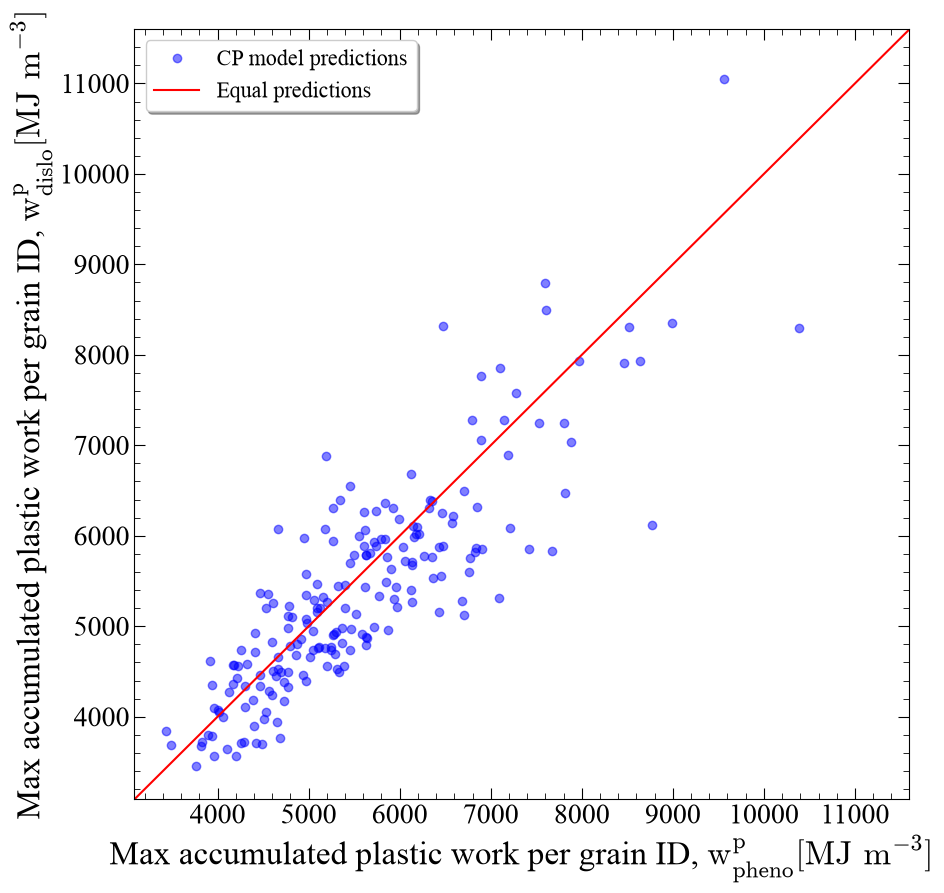

In [25]:
CPanalysistools.comparison_plot(max_pheno_apsed_from_grains, 
                                max_dislo_apsed_from_grains, 
                                r"Max accumulated plastic work per grain ID, $\text{w}^{\text{p}}_{\text{pheno}} [\text{MJ m}^{-3}]$", 
                                r"Max accumulated plastic work per grain ID, $\text{w}^{\text{p}}_{\text{dislo}} [\text{MJ m}^{-3}]$",
                                savefig = True,
                                fig_name = "../figures/accumulated_plastic_work/max_APSED_per_grain_200_grains_128_VE.png")

### Plots of stress triaxiality against von Mises strain

Text(0, 0.5, 'Phenomenological CP triaxiality, $T_{\\sigma}$')

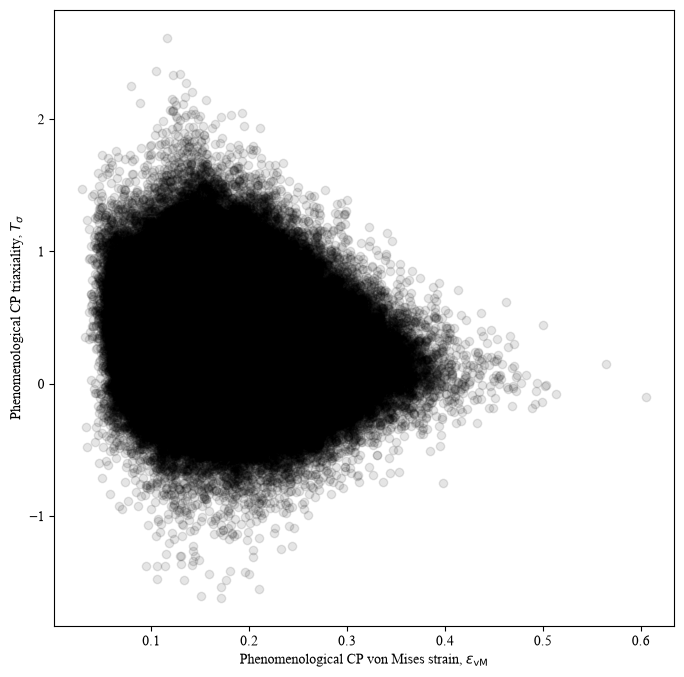

In [8]:
%matplotlib inline
fig_pheno_triax_vM_strain,  ax_pheno_triax_vM_strain = plt.subplots(1,1,figsize = (8,8))
ax_pheno_triax_vM_strain.plot(pheno_vM_strain.flatten(order = 'F'), pheno_triax.flatten(order = 'F'), 'ko', ls = 'None', alpha =0.1) 
ax_pheno_triax_vM_strain.set_xlabel(r"Phenomenological CP von Mises strain, $\varepsilon_{\text{vM}}$")
ax_pheno_triax_vM_strain.set_ylabel(r"Phenomenological CP triaxiality, $T_{\sigma}$")
                                #axis_label_fontsize = 30,
                                #tick_label_fontsize = 24,


Text(0, 0.5, 'Dislocation density CP triaxiality, $T_{\\sigma}$')

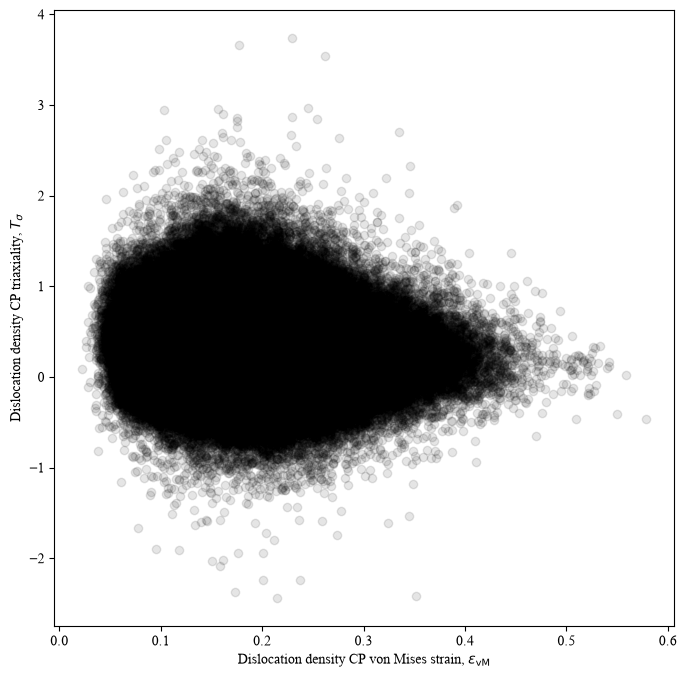

In [9]:
fig_dislo_triax_vM_strain,  ax_dislo_triax_vM_strain = plt.subplots(1,1,figsize = (8,8))
ax_dislo_triax_vM_strain.plot(dislo_vM_strain.flatten(order = 'F'), dislo_triax.flatten(order = 'F'), 'ko', ls = 'None', alpha =0.1) 
ax_dislo_triax_vM_strain.set_xlabel(r"Dislocation density CP von Mises strain, $\varepsilon_{\text{vM}}$")
ax_dislo_triax_vM_strain.set_ylabel(r"Dislocation density CP triaxiality, $T_{\sigma}$")

# Distance from GBs against metrics of interest

In [30]:
voxel_coords_128_cube = CPanalysistools.extract_voxel_coords()

In [31]:
voronoi_seeds_200_grains = np.loadtxt("../microstructure_seeds/rolled_copper_texture_200_orientations_random_seeds.csv", delimiter = ",")[:,:3]

In [32]:
min_dist_to_GBs = CPanalysistools.min_distance_from_voxels_to_nearest_GB_continuous(voronoi_seeds_200_grains, voxel_coords_128_cube.reshape((128**3, 3), order = 'F'))

In [7]:
voxel_coords_128_cube.flatten(order='F')[0]

np.float64(3.90625e-06)

KDE plots with outliers

In [ ]:
pheno_triax_mean = np.mean(pheno_triax.flatten(order='F'))
pheno_triax_stdev = np.std(pheno_triax.flatten(order='F'))

pheno_triax_outliers = []
pheno_outlier_idxs = []

for idx, triax in enumerate(pheno_triax.flatten(order='F')):
    if (triax > pheno_triax_mean + 3*pheno_triax_stdev) or (triax < pheno_triax_mean - 3*pheno_triax_stdev):
        pheno_triax_outliers.append(triax)
        pheno_outlier_idxs.append(idx)

pheno_triax_outliers = np.array(pheno_triax_outliers)
pheno_outlier_idxs = np.array(pheno_outlier_idxs)

In [30]:
pheno_triax_outliers, pheno_outlier_idxs

(array([ 0.97086343,  0.9668529 , -0.52660521, ...,  1.01732265,
         0.99102067,  1.10663574], shape=(20055,)),
 array([    347,     390,    1672, ..., 2096858, 2096984, 2097115],
       shape=(20055,)))

In [34]:
min_dist_to_GBs_pheno_outliers = min_dist_to_GBs[pheno_outlier_idxs]

KDE plots with outliers for vM strain and APSED

In [34]:
def extract_99_percent_outliers(data, min_dist_to_GBs, normalisation, save_idxs=False, fname=None):
    rng = np.random.default_rng(42)
    idx = rng.choice(len(min_dist_to_GBs), 100000, replace=False)

    kde = scipy.stats.gaussian_kde(np.vstack([(min_dist_to_GBs/(normalisation.flatten(order='F')[0]*2))[idx], data.flatten(order='F')[idx]]))
    x_grid = np.linspace((min_dist_to_GBs/(normalisation.flatten(order='F')[0]*2)).min(), (min_dist_to_GBs/(normalisation.flatten(order='F')[0]*2)).max(), 300)
    y_grid = np.linspace(data.flatten(order = 'F').min(), data.flatten(order = 'F').max(), 300)
    X, Y = np.meshgrid(x_grid, y_grid)

    Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)

    z_sorted = np.sort(Z.ravel())[::-1]

    cumulative = np.cumsum(z_sorted)
    cumulative /= cumulative[-1]

    threshold_99 = z_sorted[np.searchsorted(cumulative, 0.99)]

    point_density = np.empty(len(min_dist_to_GBs))
    chunk_size = 50000

    for start in tqdm(range(0, len(min_dist_to_GBs), chunk_size)):
        stop = min(start + chunk_size, len(min_dist_to_GBs))
        point_density[start:stop] = kde(np.vstack([(min_dist_to_GBs/(normalisation.flatten(order='F')[0]*2))[start:stop], data.flatten(order='F')[start:stop]]))

    outside_99 = point_density < threshold_99

    outlier_indices = np.where(outside_99 ==True)

    if save_idxs == True:
        np.save(f"{fname}.npy", outlier_indices)

    return outlier_indices

In [35]:
pheno_vM_strain_outlier_idxs = extract_99_percent_outliers(pheno_vM_strain, min_dist_to_GBs, normalisation=voxel_coords_128_cube)

100%|██████████| 42/42 [08:48<00:00, 12.57s/it]


In [36]:
np.save("pheno_vM_strain_outlier_idxs.npy", pheno_vM_strain_outlier_idxs)

In [37]:
dislo_vM_strain_outlier_idxs = extract_99_percent_outliers(dislo_vM_strain, min_dist_to_GBs, normalisation=voxel_coords_128_cube)

100%|██████████| 42/42 [09:04<00:00, 12.96s/it]


In [38]:
np.save("dislo_vM_strain_outlier_idxs.npy", dislo_vM_strain_outlier_idxs)

In [67]:
pheno_apsed_outlier_idxs = extract_99_percent_outliers(pheno_apsed, min_dist_to_GBs, normalisation=voxel_coords_128_cube)

100%|██████████| 42/42 [08:59<00:00, 12.85s/it]


In [68]:
np.save("pheno_apsed_outlier_idxs.npy", pheno_apsed_outlier_idxs)

In [69]:
dislo_apsed_outlier_idxs = extract_99_percent_outliers(dislo_apsed, min_dist_to_GBs, normalisation=voxel_coords_128_cube)

100%|██████████| 42/42 [08:58<00:00, 12.82s/it]


In [70]:
np.save("dislo_apsed_outlier_idxs.npy", dislo_apsed_outlier_idxs)

In [65]:
def plot_data_vs_distance_from_GB(min_dist_to_GBs, normalisation, 
                                  data1, data2, data_label, 
                                  outliermask1, outliermask2,
                                  savefig = False,
                                  fname = None):
    fig, ax = plt.subplots(1, 2, figsize=(20,6), sharey= True, sharex = True, constrained_layout = True)

    rng = np.random.default_rng(42)
    idx = rng.choice(len(min_dist_to_GBs), 100000, replace=False)
            
    ax[0].scatter((min_dist_to_GBs/(normalisation.flatten(order='F')[0]*2))[outliermask1],data1.flatten(order='F')[outliermask1],marker='.',color='mediumorchid',alpha=0.2)
    ax[1].scatter((min_dist_to_GBs/(normalisation.flatten(order='F')[0]*2))[outliermask2],data2.flatten(order = 'F')[outliermask2],marker='.',color='green',alpha=0.2)

    min_val = min(min(data1.flatten(order = 'F')), min(data2.flatten(order = 'F')))
    max_val = max(max(data1.flatten(order = 'F')), max(data2.flatten(order = 'F')))

    ax[0].set_xlim(0)
    ax[0].set_ylim(min_val - 0.01, max_val + 0.01)

    ax[0].set_title("Phenomenological CP", fontsize = 24)
    ax[1].set_title("Dislocation Density CP", fontsize = 24)
    ax[0].set_xlabel("Distance to nearest grain boundary (number of voxels)", fontsize = 20)
    ax[1].set_xlabel("Distance to nearest grain boundary (number of voxels)", fontsize = 20)
    ax[0].set_ylabel(data_label, fontsize = 20, math_fontfamily = 'cm')

    ax[0].tick_params(which = 'both', direction = 'in', top = True, right = True, labelsize = 18)
    ax[0].tick_params(which = 'minor', length = 4)
    ax[0].tick_params(which = 'major', length = 8)
    ax[1].tick_params(which = 'both', direction = 'in', top = True, right = True, labelsize = 18)
    ax[1].tick_params(which = 'minor', length = 4)
    ax[1].tick_params(which = 'major', length = 8)

    ax[0].xaxis.set_minor_locator(AutoMinorLocator(4))
    ax[0].yaxis.set_minor_locator(AutoMinorLocator(4))
    ax[1].xaxis.set_minor_locator(AutoMinorLocator(4))
    ax[1].yaxis.set_minor_locator(AutoMinorLocator(4))

    sns.kdeplot(x=(min_dist_to_GBs/(normalisation.flatten(order='F')[0]*2))[idx], y=data1.flatten(order = 'F')[idx], levels = [0.01,0.05,0.25,0.5], ax = ax[0], cmap = "copper")
    sns.kdeplot(x=(min_dist_to_GBs/(normalisation.flatten(order='F')[0]*2))[idx], y=data2.flatten(order = 'F')[idx], levels = [0.01,0.05,0.25,0.5], ax = ax[1], cmap = "copper")

    if savefig==True:
        plt.savefig(f"../figures/{fname}.png", dpi=800)

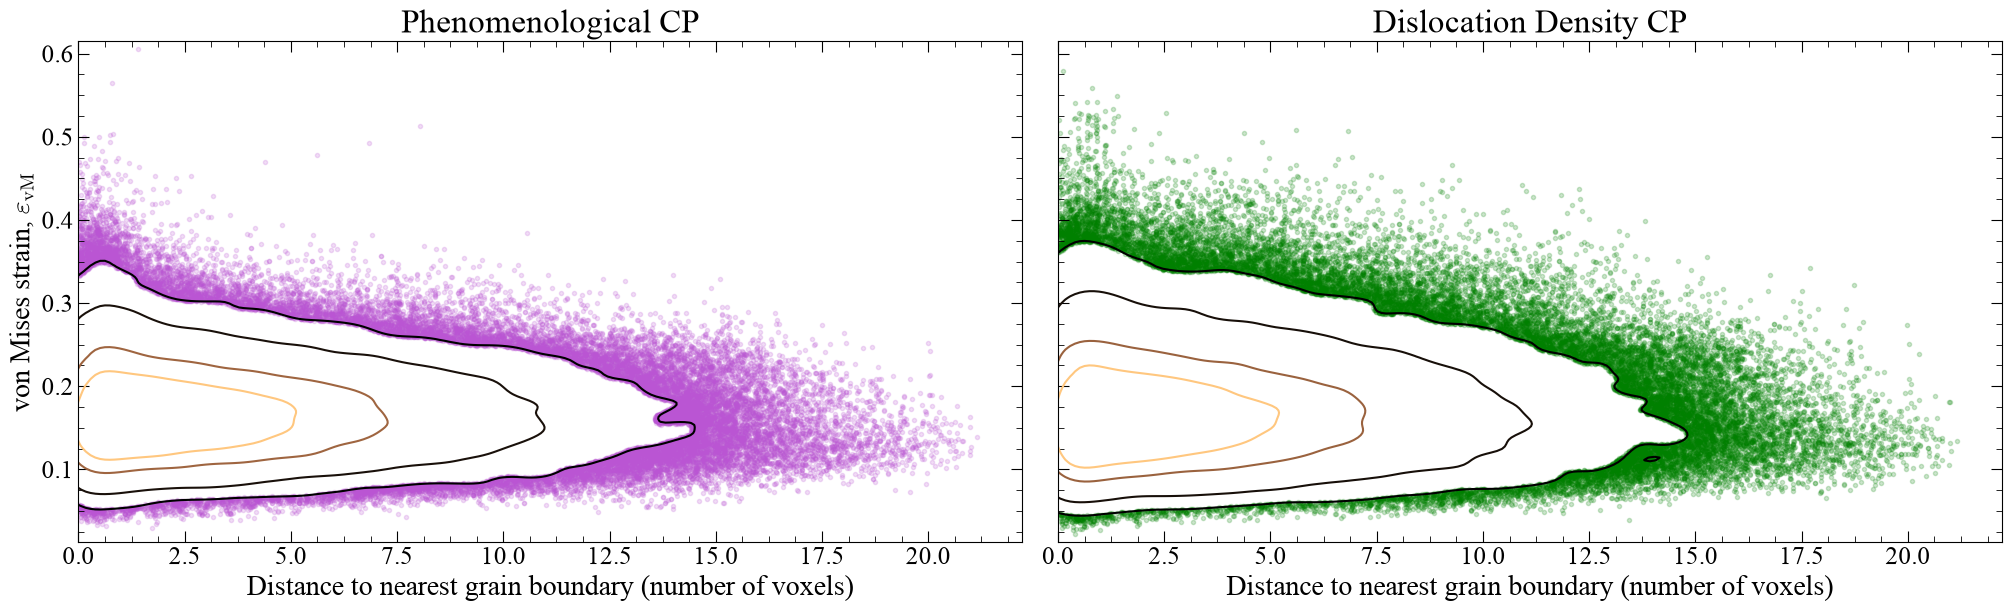

In [71]:
plot_data_vs_distance_from_GB(min_dist_to_GBs, voxel_coords_128_cube, 
                                  pheno_vM_strain, dislo_vM_strain, r"von Mises strain, $\varepsilon_{\text{vM}}$", 
                                  pheno_vM_strain_outlier_idxs, dislo_vM_strain_outlier_idxs,
                                  savefig = True,
                                  fname = "vM_strain_vs_distance_from_GBs_KDE_plot_with_outliers")

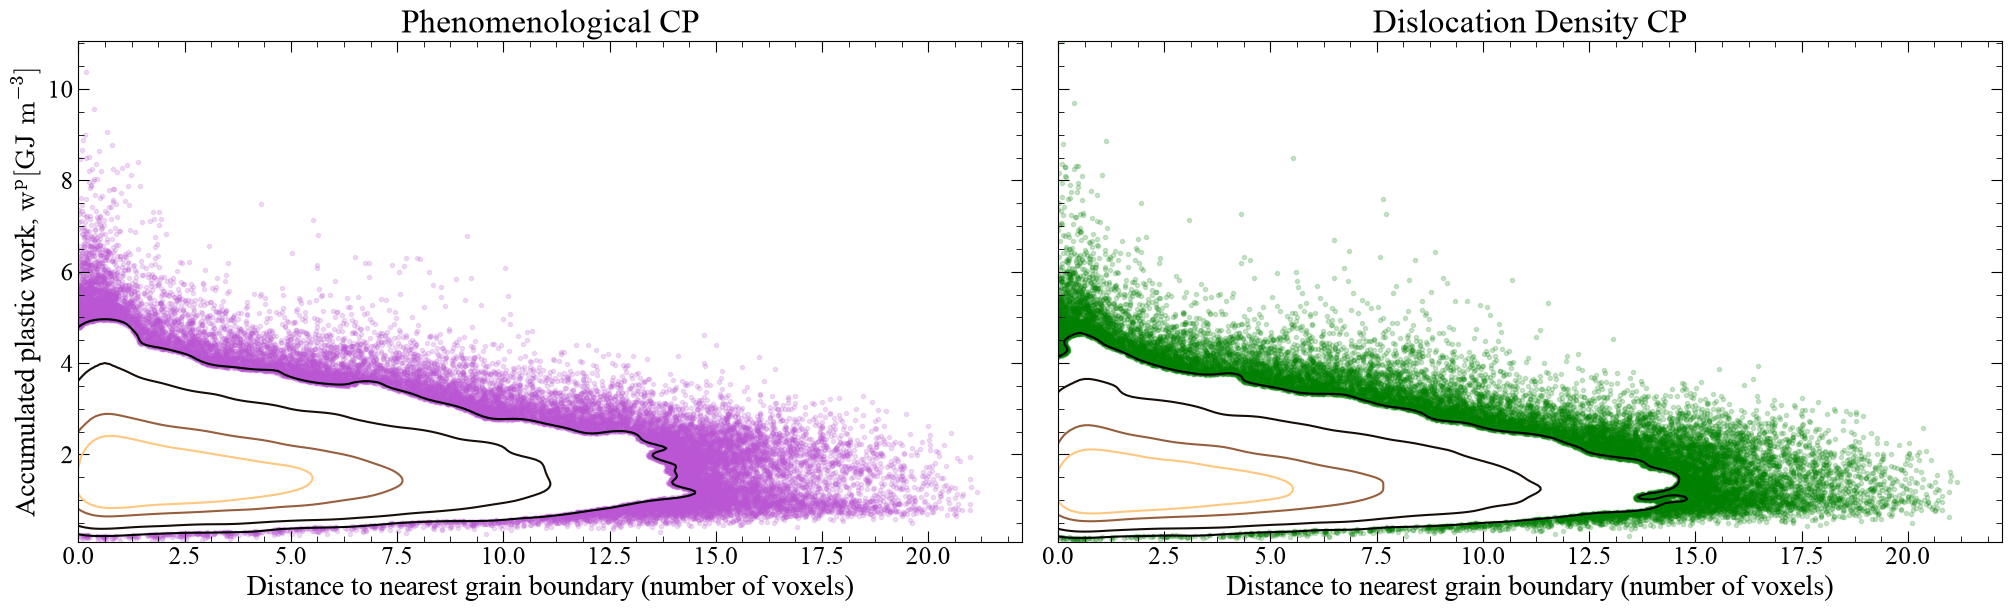

In [73]:
plot_data_vs_distance_from_GB(min_dist_to_GBs, voxel_coords_128_cube, 
                                  pheno_apsed*1e-9, dislo_apsed*1e-9, r"Accumulated plastic work, $\text{w}^{\text{p}} [\text{GJ m}^{-3}]$", 
                                  pheno_apsed_outlier_idxs, dislo_apsed_outlier_idxs,
                                  savefig = True,
                                  fname = "APSED_vs_distance_from_GBs_KDE_plot_with_outliers")

In [74]:
pheno_triax_outlier_idxs = np.load("pheno_outlier_indices.npy")
dislo_triax_outlier_idxs = np.load("dislo_outlier_indices.npy")

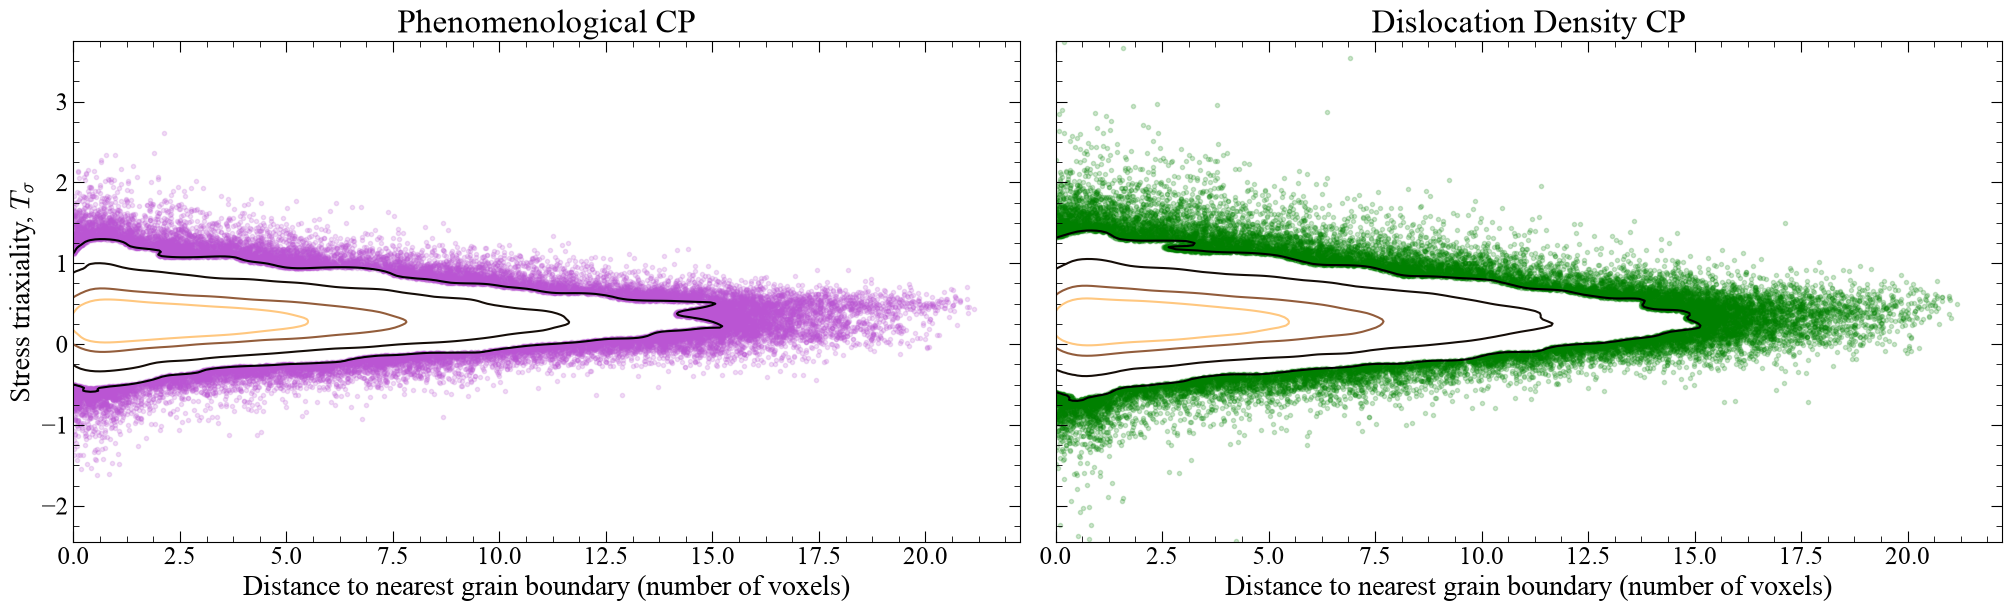

In [75]:
plot_data_vs_distance_from_GB(min_dist_to_GBs, voxel_coords_128_cube, 
                                  pheno_triax, dislo_triax, r"Stress triaxiality, $T_{\sigma}$", 
                                  pheno_triax_outlier_idxs, dislo_triax_outlier_idxs,
                                  savefig = True,
                                  fname = "triax_vs_distance_from_GBs_KDE_plot_with_outliers")

### Pheno triax outliers

In [8]:
rng = np.random.default_rng(42)
idx = rng.choice(len(min_dist_to_GBs), 100000, replace=False)

In [9]:
pheno_kde = scipy.stats.gaussian_kde(np.vstack([(min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2))[idx], pheno_triax.flatten(order='F')[idx]]))

pheno_x_grid = np.linspace((min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2)).min(), (min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2)).max(), 300)
pheno_y_grid = np.linspace(pheno_triax.flatten(order = 'F').min(), pheno_triax.flatten(order = 'F').max(), 300)
pheno_X, pheno_Y = np.meshgrid(pheno_x_grid, pheno_y_grid)

pheno_Z = pheno_kde(np.vstack([pheno_X.ravel(), pheno_Y.ravel()])).reshape(pheno_X.shape)

In [10]:
pheno_z_sorted = np.sort(pheno_Z.ravel())[::-1]

# Cumulative probability mass
cumulative = np.cumsum(pheno_z_sorted)
cumulative /= cumulative[-1]

# Density threshold enclosing 99% of the KDE probability mass
pheno_threshold_99 = pheno_z_sorted[
    np.searchsorted(cumulative, 0.99)
]

print("99% density threshold:", pheno_threshold_99)

99% density threshold: 0.0023272938681218867


In [ ]:
pheno_point_density = np.empty(len(min_dist_to_GBs))
chunk_size = 50000

for start in tqdm(range(0, len(min_dist_to_GBs), chunk_size)):
    stop = min(start + chunk_size, len(min_dist_to_GBs))
    pheno_point_density[start:stop] = pheno_kde(np.vstack([(min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2))[start:stop], pheno_triax.flatten(order='F')[start:stop]]))

pheno_outside_99 = pheno_point_density < pheno_threshold_99

100%|██████████| 42/42 [08:54<00:00, 12.72s/it]


In [13]:
np.save("pheno_outlier_indices.npy", pheno_outside_99)

In [19]:
pheno_outlier_indices = np.where(pheno_outside_99 ==True)

### Dislo triax outliers

In [28]:
dislo_kde = scipy.stats.gaussian_kde(np.vstack([(min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2))[idx], dislo_triax.flatten(order='F')[idx]]))

dislo_x_grid = np.linspace((min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2)).min(), (min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2)).max(), 300)
dislo_y_grid = np.linspace(dislo_triax.flatten(order = 'F').min(), dislo_triax.flatten(order = 'F').max(), 300)
dislo_X, dislo_Y = np.meshgrid(dislo_x_grid, dislo_y_grid)

dislo_Z = dislo_kde(np.vstack([dislo_X.ravel(), dislo_Y.ravel()])).reshape(dislo_X.shape)

In [35]:
dislo_z_sorted = np.sort(dislo_Z.ravel())[::-1]

# Cumulative probability mass
dislo_cumulative = np.cumsum(dislo_z_sorted)
dislo_cumulative /= dislo_cumulative[-1]

# Density threshold enclosing 99% of the KDE probability mass
dislo_threshold_99 = dislo_z_sorted[
    np.searchsorted(dislo_cumulative, 0.99)
]

print("99% density threshold:", dislo_threshold_99)

99% density threshold: 0.0018831628838815852


In [36]:
dislo_point_density = np.empty(len(min_dist_to_GBs))

for start in tqdm(range(0, len(min_dist_to_GBs), chunk_size)):
    stop = min(start + chunk_size, len(min_dist_to_GBs))
    dislo_point_density[start:stop] = dislo_kde(np.vstack([(min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2))[start:stop], dislo_triax.flatten(order='F')[start:stop]]))

dislo_outside_99 = dislo_point_density < dislo_threshold_99

100%|██████████| 42/42 [09:03<00:00, 12.93s/it]


In [37]:
np.save("dislo_outlier_indices.npy", dislo_outside_99)

In [38]:
dislo_outlier_indices = np.where(dislo_outside_99 ==True)

In [42]:
pheno_outlier_indices, dislo_outlier_indices

((array([      3,       4,       5, ..., 2097022, 2097115, 2097125],
        shape=(20589,)),),
 (array([      5,       6,       7, ..., 2096763, 2096764, 2097150],
        shape=(21127,)),))

### Plots

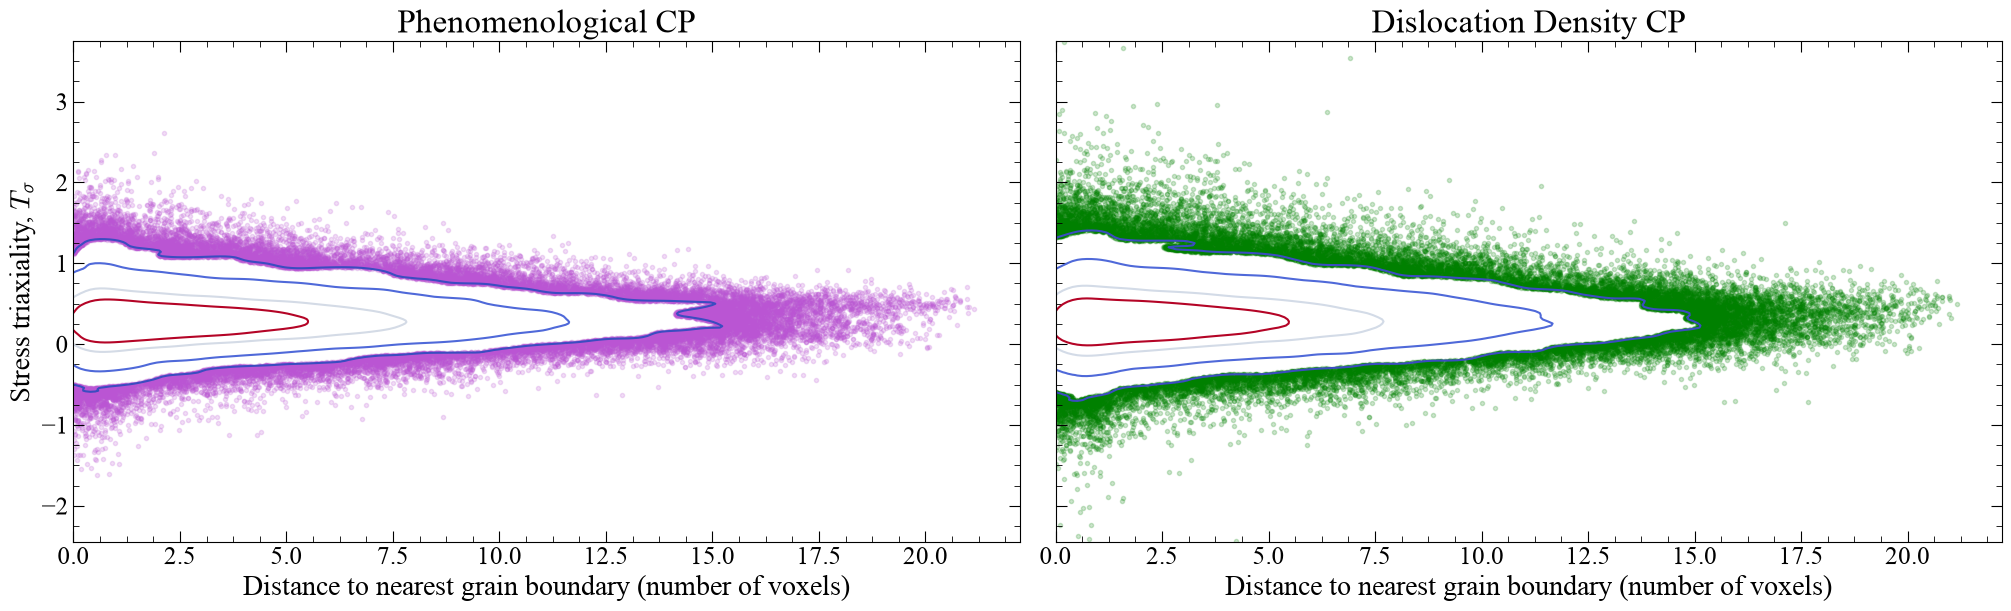

In [41]:
%matplotlib inline
import seaborn as sns

fig_triax_gb, ax_triax_gb = plt.subplots(1, 2, figsize=(20,6), sharey= True, sharex = True, constrained_layout = True)

            
ax_triax_gb[0].scatter((min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2))[pheno_outlier_indices],pheno_triax.flatten(order='F')[pheno_outlier_indices],marker='.',color='mediumorchid',alpha=0.2)
ax_triax_gb[1].scatter((min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2))[dislo_outlier_indices],dislo_triax.flatten(order = 'F')[dislo_outlier_indices],marker='.',color='green',alpha=0.2)

min_triax_val = min(min(pheno_triax.flatten(order = 'F')), min(dislo_triax.flatten(order = 'F')))
max_triax_val = max(max(pheno_triax.flatten(order = 'F')), max(dislo_triax.flatten(order = 'F')))

ax_triax_gb[0].set_xlim(0)
ax_triax_gb[0].set_ylim(min_triax_val - 0.01, max_triax_val + 0.01)

ax_triax_gb[0].set_title("Phenomenological CP", fontsize = 24)
ax_triax_gb[1].set_title("Dislocation Density CP", fontsize = 24)
ax_triax_gb[0].set_xlabel("Distance to nearest grain boundary (number of voxels)", fontsize = 20)
ax_triax_gb[1].set_xlabel("Distance to nearest grain boundary (number of voxels)", fontsize = 20)
ax_triax_gb[0].set_ylabel(r"Stress triaxiality, $T_{\sigma}$", fontsize = 20, math_fontfamily = 'cm')

ax_triax_gb[0].tick_params(which = 'both', direction = 'in', top = True, right = True, labelsize = 18)
ax_triax_gb[0].tick_params(which = 'minor', length = 4)
ax_triax_gb[0].tick_params(which = 'major', length = 8)
ax_triax_gb[1].tick_params(which = 'both', direction = 'in', top = True, right = True, labelsize = 18)
ax_triax_gb[1].tick_params(which = 'minor', length = 4)
ax_triax_gb[1].tick_params(which = 'major', length = 8)

ax_triax_gb[0].xaxis.set_minor_locator(AutoMinorLocator(4))
ax_triax_gb[0].yaxis.set_minor_locator(AutoMinorLocator(4))
ax_triax_gb[1].xaxis.set_minor_locator(AutoMinorLocator(4))
ax_triax_gb[1].yaxis.set_minor_locator(AutoMinorLocator(4))

sns.kdeplot(x=(min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2))[idx], y=pheno_triax.flatten(order = 'F')[idx], levels = [0.01,0.05,0.25,0.5], ax = ax_triax_gb[0], cmap="coolwarm")
sns.kdeplot(x=(min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2))[idx], y=dislo_triax.flatten(order = 'F')[idx], levels = [0.01,0.05,0.25,0.5], ax = ax_triax_gb[1], cmap="coolwarm")

plt.savefig("../figures/stress_triax_vs_distance_from_GBs_KDE_plot_with_outliers", dpi=800)


(0.0, 21.254710168631537)

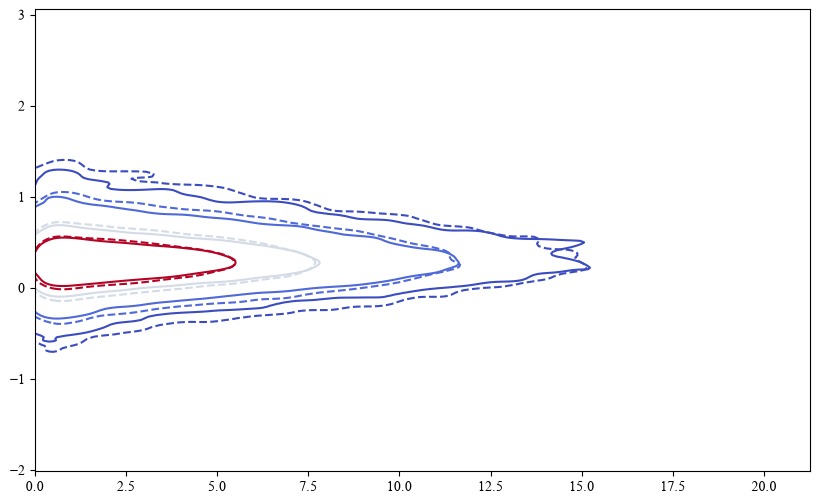

In [53]:
fig_overlay, ax_overlay = plt.subplots(1,1,figsize = (10,6))
sns.kdeplot(x=(min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2))[idx], y=pheno_triax.flatten(order = 'F')[idx], levels = [0.01,0.05,0.25,0.5], ax = ax_overlay, cmap="coolwarm")
sns.kdeplot(x=(min_dist_to_GBs/(voxel_coords_128_cube.flatten(order='F')[0]*2))[idx], y=dislo_triax.flatten(order = 'F')[idx], levels = [0.01,0.05,0.25,0.5], ax = ax_overlay, cmap="coolwarm", linestyles = "--")
ax_overlay.set_xlim(0)

### Comparison plots with distance to GBs

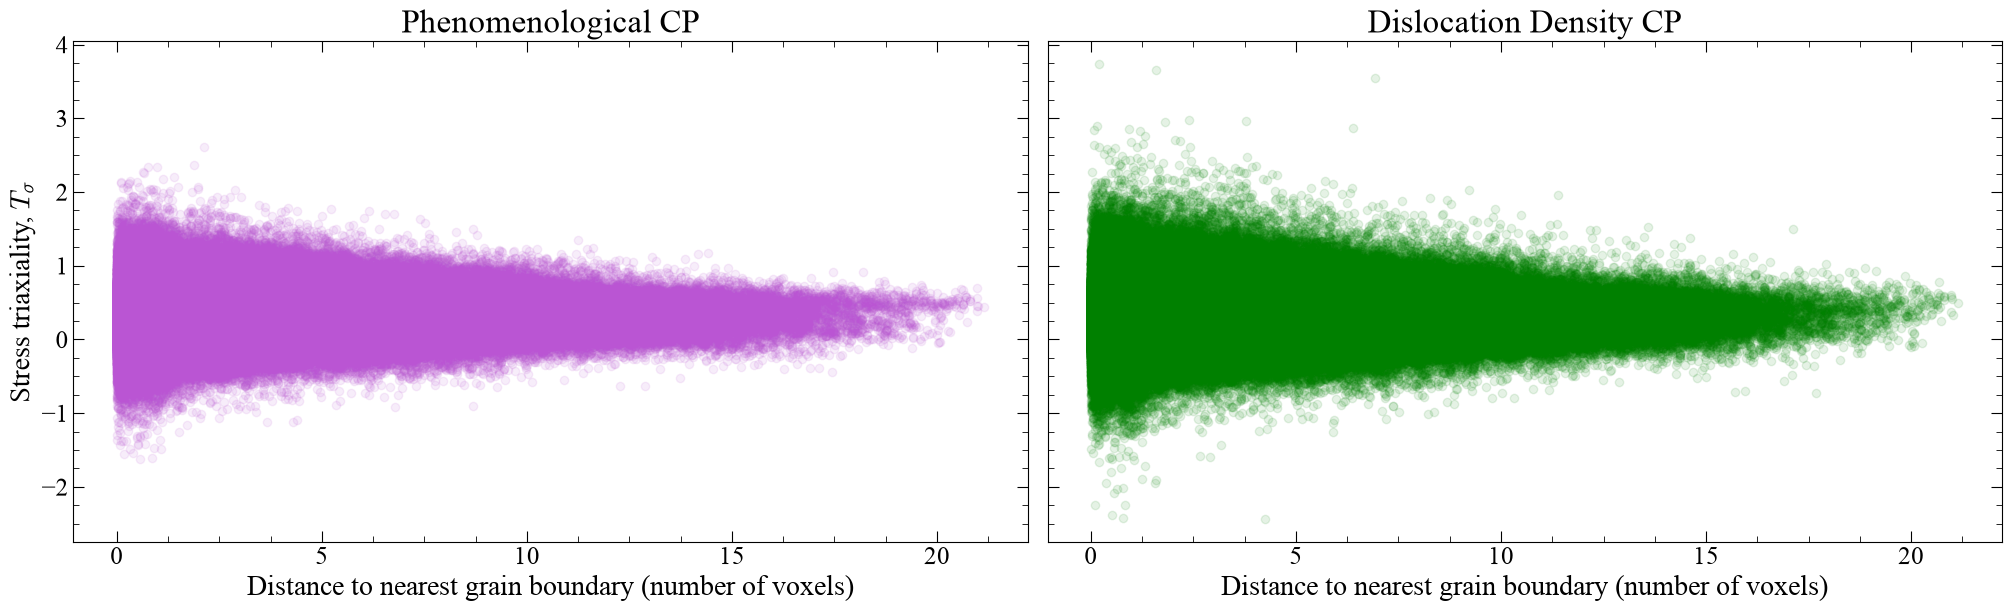

In [ ]:
# Stress triaxiality
comparison_plot_distance_to_GB(min_dist_to_GBs, voxel_coords_128_cube.flatten(order='F')[0]*2,
                               pheno_triax.flatten(order = 'F'), 
                               dislo_triax.flatten(order = 'F'),
                               r"Stress triaxiality, $T_{\sigma}$",
                               )

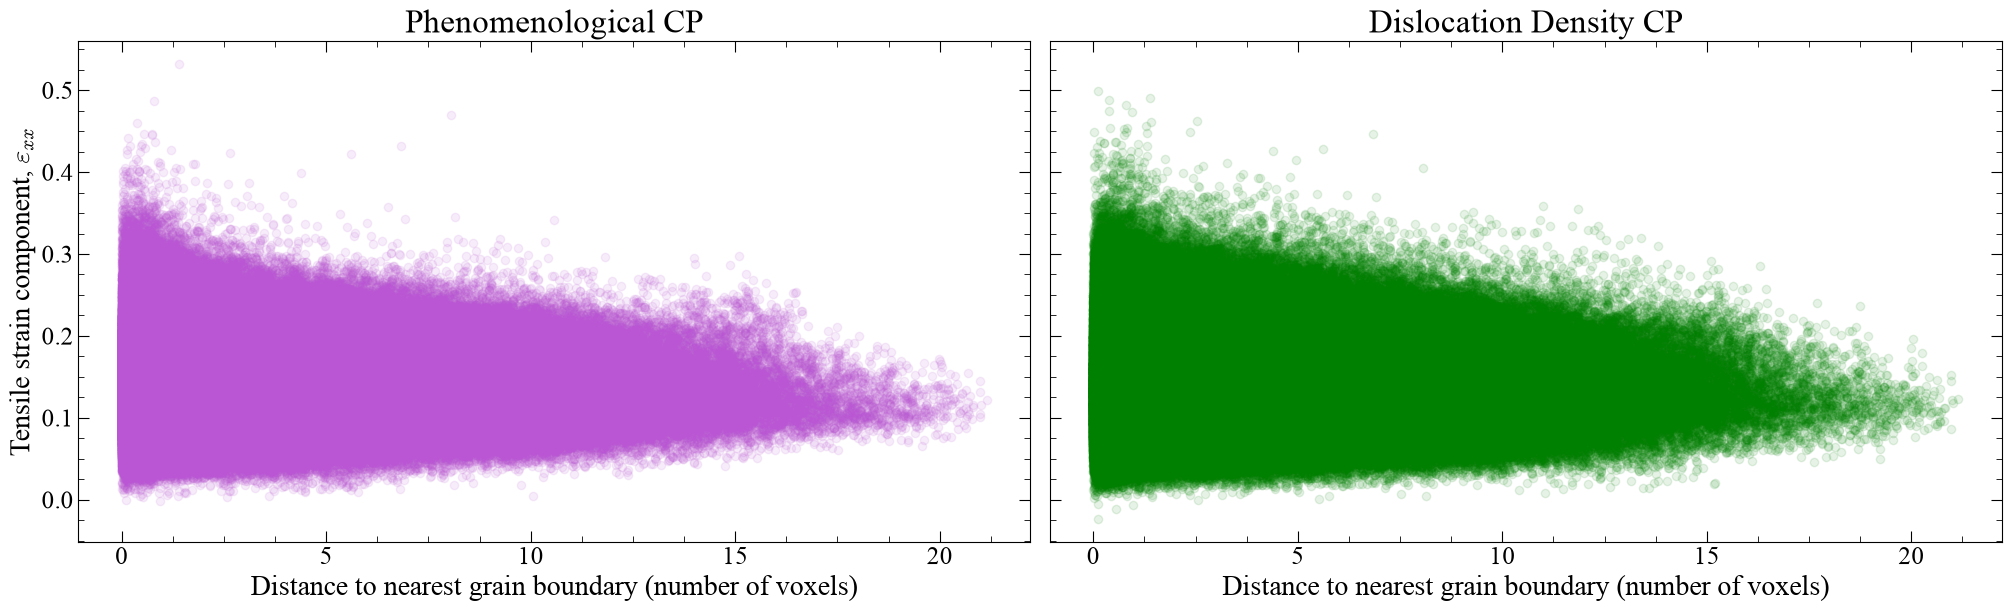

In [89]:
comparison_plot_distance_to_GB(min_dist_to_GBs, voxel_coords_128_cube.flatten(order='F')[0]*2, 
                               pheno_xx_strain.flatten(order = 'F'), 
                               dislo_xx_strain.flatten(order = 'F'),
                               r"Tensile strain component, $\varepsilon_{xx}$",
                               )

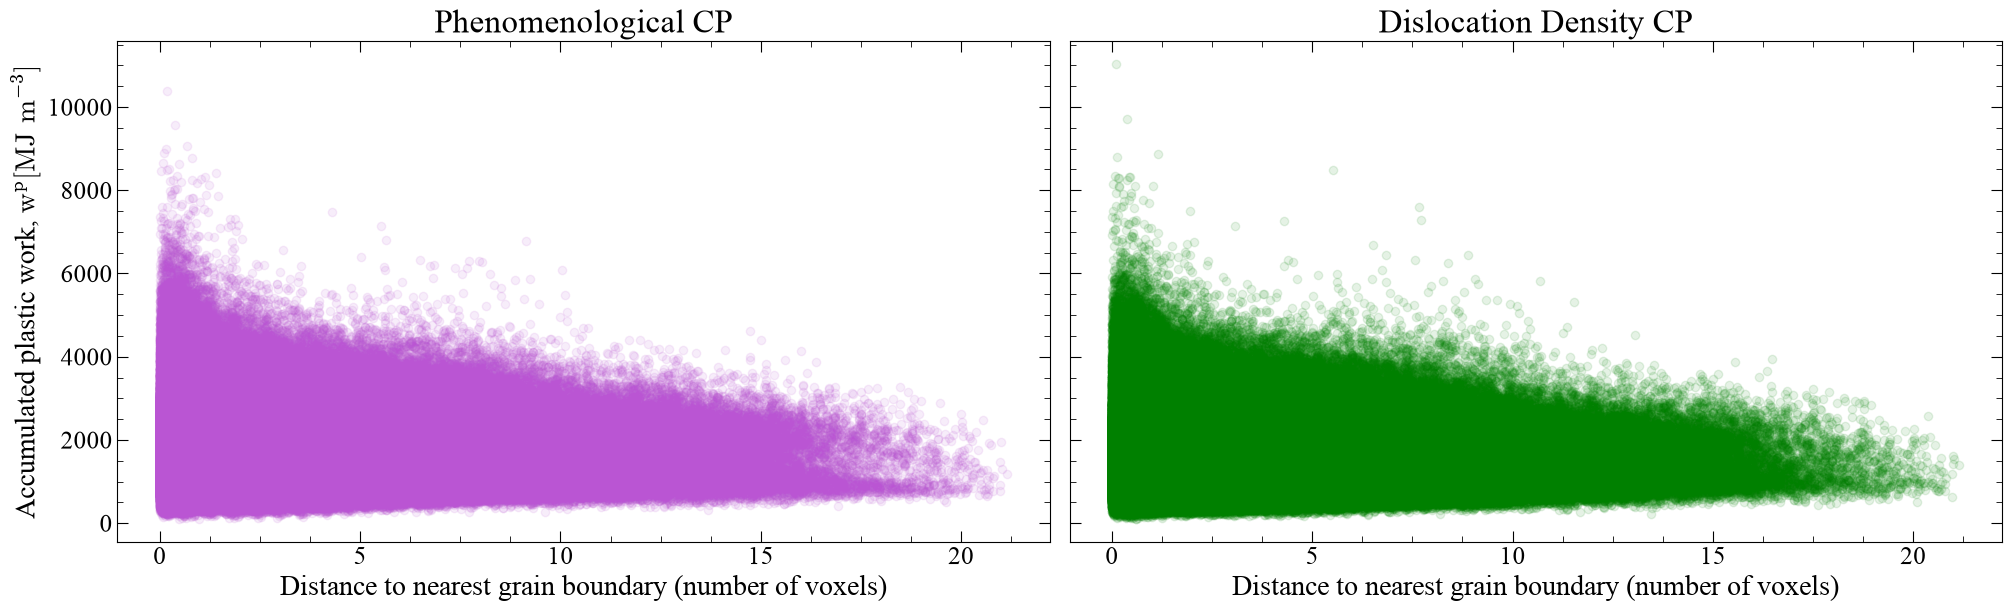

In [91]:
comparison_plot_distance_to_GB(min_dist_to_GBs, voxel_coords_128_cube.flatten(order='F')[0]*2, 
                               pheno_apsed.flatten(order = 'F')*1e-6, 
                               dislo_apsed.flatten(order = 'F')*1e-6,
                               r"Accumulated plastic work, $\text{w}^{\text{p}} [\text{MJ m}^{-3}]$",
                               )

# Test stuff

In [8]:
def extract_slip_systems(material_file):
    mat = damask.ConfigMaterial.load(material_file)
    crystal_structure = damask.Crystal(lattice = mat['phase']['Cu']['lattice'])
    slip_dirs = crystal_structure.kinematics('slip')['direction'][0]
    slip_norms = crystal_structure.kinematics('slip')['plane'][0]

    return slip_dirs, slip_norms

In [9]:
def update_slip_systems(damask_view, slip_dirs, slip_norms, rve_shape):

    rot_matrices = damask.Rotation(damask_view.get('O')).reshape(rve_shape, order = 'F').as_matrix()

    #print(rot_matrices.shape)

    slip_dirs = np.broadcast_to(slip_dirs, [128,128,128,12,3])
    slip_norms = np.broadcast_to(slip_norms, [128,128,128,12,3])

    new_slip_dirs = np.einsum('...ij, ...ki -> ...kj', rot_matrices, slip_dirs)
    new_slip_norms = np.einsum('...ij, ...ki -> ...kj', rot_matrices, slip_norms)

    #print(new_slip_dirs.shape, new_slip_norms.shape)
    
    #all_new_slip_dirs = []
    #all_new_slip_norms = []


    #for i in range(len(rot_matrices)):
    #    new_slip_dirs = []
    #    new_slip_norms = []
    #    for j in range(len(slip_dirs)):
    #        new_slip_dir = rot_matrices[i] @ slip_dirs[j]
    #        new_slip_norm = rot_matrices[i] @ slip_norms[j]
    #        new_slip_dirs.append(new_slip_dir)
    #        new_slip_norms.append(new_slip_norm)
            
    #    all_new_slip_dirs.append(new_slip_dirs)
    #    all_new_slip_norms.append(new_slip_norms)

    return new_slip_dirs, new_slip_norms

In [13]:
def extract_accum_plastic_strain_energy_density(damask_file, mat_file, rve_shape):
    result = damask.Result(damask_file)

    slip_dirs, slip_norms = extract_slip_systems(mat_file)

    total_plastic_work_arrs = []

    for i in tqdm(range(len(result.increments))):
        x = result.view(increments = result.increments[i])
        gamma = x.get('gamma_sl').reshape([rve_shape[0], rve_shape[1], rve_shape[2], 12], order = 'F')
        #print(f"Gamma shape = {gamma.shape}")

        if i == 0:
            new_slip_dirs = np.broadcast_to(slip_dirs, [128,128,128,12,3])
            new_slip_norms = np.broadcast_to(slip_norms, [128,128,128,12,3])

        else:
            new_slip_dirs, new_slip_norms = update_slip_systems(x, slip_dirs, slip_norms, rve_shape)

        #print(f"New slip dirs shape = {new_slip_dirs.shape}, New slip norms shape = {new_slip_norms.shape}")

        sigma = x.get('sigma').reshape([rve_shape[0], rve_shape[1], rve_shape[2], 3, 3], order = 'F')

        #print(f"Sigma shape = {sigma.shape}")

        #print(new_slip_dirs.nbytes/(1024**3), new_slip_norms.nbytes/(1024**3))

        # Calculate resolved shear stresses
        #tau = np.einsum('vij,vsi,vsj->vs', sigma, new_slip_dirs, new_slip_norms)
        #slip_product = np.einsum('...ij, ...ik -> ...ijk', new_slip_dirs, new_slip_norms)

        #tau = np.tensordot(sigma, slip_product, axes = ([4,5], [3,4]))

        tau = np.einsum('...ij, ...si, ...sj -> ...s', sigma, new_slip_dirs, new_slip_norms)

        #print(f"Tau shape = {tau.shape}")

        plastic_work = np.abs(np.multiply(tau, gamma))

        #print(f"Plastic work shape = {plastic_work.shape}")

        total_plastic_work_per_inc = np.sum(plastic_work, axis=3)

        #print(f"Total plastic work per increment shape = {total_plastic_work_per_inc.shape}")

        if i == 0:
            total_plastic_work_arrs.append(total_plastic_work_per_inc)
        else:
            total_plastic_work_current_time_inc = total_plastic_work_per_inc - total_plastic_work_arrs[i-1]
            total_plastic_work_arrs.append(total_plastic_work_current_time_inc)

    total_plastic_work_arrs = np.array(total_plastic_work_arrs) # Should be shape [12,128,128,128]  

    accum_plastic_work = np.sum(total_plastic_work_arrs, axis = 0)

    return accum_plastic_work

In [42]:
pheno_slip_dirs, pheno_slip_norms = extract_slip_systems(pheno_mat_file)
pheno_result_test = damask.Result(pheno_file)
pheno_result_view = pheno_result_test.view(increments = 0)

In [33]:
new_pheno_slip_dirs, new_pheno_slip_norms = update_slip_systems(pheno_result_view, pheno_slip_dirs, pheno_slip_norms, [128,128,128])
new_pheno_slip_dirs, new_pheno_slip_norms

(128, 128, 128, 3, 3)
(128, 128, 128, 12, 3) (128, 128, 128, 12, 3)


(array([[[[[ 0.38819601, -0.92832702,  0.99373679],
           [ 0.86640986,  0.28161946, -1.08167667],
           [-1.25460588,  0.64670756,  0.08793988],
           ...,
           [ 1.18986796,  0.73222792,  0.21921797],
           [-0.86640986, -0.28161946,  1.08167667],
           [-0.32345809, -0.45060846, -1.30089464]],
 
          [[ 0.38819601, -0.92832702,  0.99373679],
           [ 0.86640986,  0.28161946, -1.08167667],
           [-1.25460588,  0.64670756,  0.08793988],
           ...,
           [ 1.18986796,  0.73222792,  0.21921797],
           [-0.86640986, -0.28161946,  1.08167667],
           [-0.32345809, -0.45060846, -1.30089464]],
 
          [[ 0.38819601, -0.92832702,  0.99373679],
           [ 0.86640986,  0.28161946, -1.08167667],
           [-1.25460588,  0.64670756,  0.08793988],
           ...,
           [ 1.18986796,  0.73222792,  0.21921797],
           [-0.86640986, -0.28161946,  1.08167667],
           [-0.32345809, -0.45060846, -1.30089464]],
 
       

In [15]:
pheno_apsed = extract_accum_plastic_strain_energy_density(pheno_file, pheno_mat_file, rve_shape=[128,128,128])

 45%|████▍     | 45/101 [02:23<03:11,  3.43s/it]

: 

In [ ]:
dislo_apsed = extract_accum_plastic_strain_energy_density(pheno_file, pheno_mat_file, rve_shape=[128,128,128])

Grain averaged stress triaxiality

In [41]:
dislo_mf_wk = mf.Workflow(dislo_wk)

In [112]:
dislo_task = dislo_mf_wk.tasks.generate_volume_element_from_voronoi.elements

VE = dislo_task.volume_element

VE

AttributeError: 'Elements' object has no attribute 'volume_element'

In [11]:
material_IDs = CPanalysistools.extract_material_IDs(pheno_wk)

/mnt/iusers01/jf01/j38714mw/matflow_v40a7-venv/lib/python3.13/site-packages/CPanalysistools/_CPanalysistools.py:420: SyntaxWarning: invalid escape sequence '\s'
  ax.set_ylabel('True stress, $\sigma_{xx}$ (MPa)', fontsize=label_fontsize)
/mnt/iusers01/jf01/j38714mw/matflow_v40a7-venv/lib/python3.13/site-packages/CPanalysistools/_CPanalysistools.py:421: SyntaxWarning: invalid escape sequence '\e'
  ax.set_xlabel('True strain, $\epsilon_{xx}$', fontsize=label_fontsize)


TypeError: 'NoneType' object is not subscriptable

In [ ]:
CPanalysistools.grain_averaged_values(pheno_triax, material_IDs, 200)